In [1]:
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F
from collections import Counter, defaultdict
from itertools import combinations

### 1.0 Metric Algorithm

<b>Preliminary Setup</b>

In [2]:
BATCH_SIZE = 64
MAX_TOKEN = 512
RANDOM_SEED = 42
NUM_REPETITIONS = 3
NUM_QUANTILES = 100
SAMPLE_SIZE = 200
TEXT_COL = "text"
LABEL_COL = "labels"
# 明确使用第一块 CUDA GPU；不可用时停止，不静默退回 CPU。
DEVICE = "cuda:0"   

<b> Algorithm of the Metric </b>

In [3]:
def asymmetry_eta(
    x,
    bandwidth=None,
    full_matrix_memory_fraction=0.45,
    chunk_memory_fraction=0.30,
):
    """Patil-style eta on CUDA with automatic full/chunked KDE selection.

    Both execution paths evaluate the same leave-one-out Gaussian KDE and
    strict empirical CDF. Memory fractions control execution only; they do
    not change the estimator.
    """
    if not torch.cuda.is_available():
        raise RuntimeError(
            "CUDA unavailable: eta requires the CUDA-enabled Python environment"
        )

    device = torch.device(DEVICE)
    if device.type != "cuda":
        raise ValueError("DEVICE must be a CUDA device for asymmetry_eta")
    if not 0 < full_matrix_memory_fraction < 1:
        raise ValueError("full_matrix_memory_fraction must be between 0 and 1")
    if not 0 < chunk_memory_fraction < 1:
        raise ValueError("chunk_memory_fraction must be between 0 and 1")

    with torch.inference_mode():
        values = torch.as_tensor(
            np.asarray(x, dtype=float),
            device=device,
            dtype=torch.float64,
        )
        values = values[~torch.isnan(values)]
        n = values.numel()

        if n < 3:
            return np.nan

        standard_deviation = values.std(correction=1)
        quartiles = torch.quantile(
            values,
            torch.tensor([0.25, 0.75], device=device, dtype=values.dtype),
        )
        iqr = quartiles[1] - quartiles[0]
        sigma = (
            torch.minimum(standard_deviation, iqr / 1.349)
            if iqr.item() > 0
            else standard_deviation
        )
        if torch.isclose(
            sigma,
            torch.zeros_like(sigma),
            rtol=1e-5,
            atol=1e-8,
        ).item():
            sigma = (
                standard_deviation
                if standard_deviation.item() > 0
                else values.new_tensor(1.0)
            )

        h = (
            values.new_tensor(bandwidth)
            if bandwidth is not None
            else 0.9 * sigma * n ** (-1 / 5)
        )
        if h.item() <= 0:
            h = 1.06 * (
                standard_deviation
                if standard_deviation.item() > 0
                else values.new_tensor(1.0)
            ) * n ** (-1 / 5)

        free_bytes, _ = torch.cuda.mem_get_info(device)
        element_bytes = values.element_size()
        # One dense kernel plus temporary allocator headroom.
        estimated_full_bytes = int(n * n * element_bytes * 1.35)
        full_matrix_budget = int(free_bytes * full_matrix_memory_fraction)
        use_full_matrix = estimated_full_bytes <= full_matrix_budget
        normalizer = (2 * np.pi) ** -0.5

        if use_full_matrix:
            kernel = (values.unsqueeze(0) - values.unsqueeze(1)) / h
            kernel.square_().mul_(-0.5).exp_().mul_(normalizer)
            kernel.fill_diagonal_(0.0)
            f_hat = kernel.sum(dim=1) / ((n - 1) * h)
            del kernel
            execution_mode = "full"
            chunk_size = n
        else:
            # Choose the largest safe row chunk from current free memory.
            chunk_budget = int(free_bytes * chunk_memory_fraction)
            estimated_bytes_per_row = max(1, int(n * element_bytes * 1.35))
            chunk_size = max(1, min(n, chunk_budget // estimated_bytes_per_row))
            f_hat = torch.empty_like(values)

            for start in range(0, n, chunk_size):
                end = min(start + chunk_size, n)
                kernel = (
                    values.unsqueeze(0)
                    - values[start:end].unsqueeze(1)
                ) / h
                kernel.square_().mul_(-0.5).exp_().mul_(normalizer)
                kernel[
                    torch.arange(end - start, device=device),
                    torch.arange(start, end, device=device),
                ] = 0.0
                f_hat[start:end] = kernel.sum(dim=1) / ((n - 1) * h)
                del kernel

            execution_mode = "chunked"

        # searchsorted(left) is the strict empirical CDF count: # {X_j < X_i}.
        sorted_values = torch.sort(values).values
        F_hat = torch.searchsorted(
            sorted_values,
            values,
            right=False,
        ).to(values.dtype) / (n - 1)

        if (
            f_hat.std(correction=1).item() == 0
            or F_hat.std(correction=1).item() == 0
        ):
            return np.nan

        eta = -torch.corrcoef(torch.stack((f_hat, F_hat)))[0, 1]

        # Expose the last decision for monitoring without printing 1000 lines.
        asymmetry_eta.last_execution = {
            "device": str(device),
            "gpu": torch.cuda.get_device_name(device),
            "n": int(n),
            "mode": execution_mode,
            "chunk_size": int(chunk_size),
            "estimated_full_gib": estimated_full_bytes / 1024**3,
            "free_gib_at_start": free_bytes / 1024**3,
        }

        return eta.item()


In [4]:
def chi2_distance(dist1, dist2, bins=50, value_range=(-1, 1), eps=1e-12):
    """对称 χ² 直方图距离；默认使用 cosine 的固定范围，不是 χ² 检验。"""
    dist1 = np.asarray(dist1, dtype=float)
    dist2 = np.asarray(dist2, dtype=float)
    for name, values in [("dist1", dist1), ("dist2", dist2)]:
        if values.ndim != 1 or values.size == 0:
            raise ValueError(f"{name} must be a non-empty one-dimensional array")
        if not np.isfinite(values).all():
            raise ValueError(f"{name} must contain only finite values")
    if isinstance(bins, (bool, np.bool_)) or not isinstance(bins, (int, np.integer)) or bins < 1:
        raise ValueError("bins must be a positive integer")
    if not np.isfinite(eps) or eps <= 0:
        raise ValueError("eps must be finite and positive")

    if value_range is not None:
        bounds = np.asarray(value_range, dtype=float)
        if bounds.shape != (2,) or not np.isfinite(bounds).all() or bounds[0] >= bounds[1]:
            raise ValueError("value_range must contain two finite, increasing bounds")
        low, high = bounds
        # 不允许 histogram 静默丢弃范围之外的分数。
        if any(((values < low) | (values > high)).any() for values in (dist1, dist2)):
            raise ValueError("Input values fall outside value_range; check the scores or range")
        value_range = (low, high)

    # 显式传 None 时，依据两组数据共同确定边界，避免只覆盖 dist1。
    bin_edges = np.histogram_bin_edges(
        np.concatenate([dist1, dist2]), bins=bins, range=value_range
    )
    hist1, _ = np.histogram(dist1, bins=bin_edges)
    hist2, _ = np.histogram(dist2, bins=bin_edges)
    if hist1.sum() == 0 or hist2.sum() == 0:
        raise ValueError("Both histograms must contain at least one observation")

    p = hist1 / hist1.sum()
    q = hist2 / hist2.sum()
    chi_dist = 0.5 * np.sum((p - q) ** 2 / (p + q + eps))
    return float(chi_dist)


<b>Data sample and embedding extraction </b>

In [5]:
def sample_from_length_groups(
    df,
    text_col,
    sample_size=SAMPLE_SIZE,
    num_quantiles=NUM_QUANTILES,
    random_seed=RANDOM_SEED,
    length_fn=None,
    length_col="length",
    group_col="quantiles",
    return_grouped=False,
):
    """按文本长度分位组无放回抽样，不修改输入或依赖标签格式。

    默认长度是空白分隔词数。length_fn 可传入接收单篇文本并返回长度的函数，
    例如 len（字符数），或 lambda text: len(tokenizer.encode(text))。
    返回原有列和原始文本，并新增 length_col 和 group_col（Q1、Q2……）。
    缺失、空白文本不参与抽样。return_grouped=True 时返回
    (sampled_df, grouped_df)，后者包含全部有效文章的长度和分组，供后续复用。
    """
    if len({text_col, length_col, group_col}) != 3:
        raise ValueError("Text, length and group column names must be different")
    if length_col in df.columns or group_col in df.columns:
        raise ValueError("Length/group output columns already exist; choose unused output names")
    if text_col not in df.columns:
        raise ValueError(f"Missing text column: {text_col}")
    for name, value in [("sample_size", sample_size), ("num_quantiles", num_quantiles)]:
        if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{name} must be a positive integer")

    text = df[text_col].fillna("").astype(str).str.strip()
    pool = df.loc[text.ne("")].copy().reset_index(drop=True)
    text = text.loc[text.ne("")].reset_index(drop=True)
    if sample_size > len(pool):
        raise ValueError(f"Requested {sample_size} rows, but only {len(pool)} valid texts")

    lengths = text.str.split().str.len() if length_fn is None else text.map(length_fn)
    lengths = pd.to_numeric(lengths, errors="raise")
    if not np.isfinite(lengths.to_numpy(dtype=float)).all() or lengths.lt(0).any():
        raise ValueError("Text lengths must be finite, non-negative numbers")

    q = min(num_quantiles, sample_size, lengths.nunique())
    # 相同长度不拆组；所有文本长度相同时使用一个组。
    groups = (
        pd.Series(np.zeros(len(pool), dtype=int))
        if q <= 1 else pd.qcut(lengths, q=q, labels=False, duplicates="drop")
    )
    # 分组基于完整有效数据，而不是抽样后的数据。
    pool[length_col] = lengths.to_numpy()
    pool[group_col] = pd.Categorical(
        groups.map(lambda group: f"Q{int(group) + 1}"),
        categories=[f"Q{int(group) + 1}" for group in sorted(groups.unique())],
        ordered=True,
    )
    group_indices = list(groups.groupby(groups, sort=True).groups.values())
    rng = np.random.default_rng(random_seed)
    base_n = sample_size // len(group_indices)
    selected = []
    for indices in group_indices:
        selected.extend(rng.choice(
            np.asarray(indices), size=min(base_n, len(indices)), replace=False
        ).tolist())

    # 分位组不足或较小时，从未选中的行补足目标数量。
    remaining_n = sample_size - len(selected)
    if remaining_n:
        remaining_indices = np.setdiff1d(np.arange(len(pool)), selected)
        selected.extend(rng.choice(remaining_indices, size=remaining_n, replace=False).tolist())
    rng.shuffle(selected)
    sampled_df = pool.iloc[selected].copy().reset_index(drop=True)
    sampled_lengths = lengths.iloc[selected]
    print("Valid texts:", len(pool))
    print("Length groups:", len(group_indices))
    print("Actual sample size:", len(sampled_df))
    print("Length measure:", "whitespace word count" if length_fn is None else "custom length_fn")
    print("Sample length min / mean / max:",
          sampled_lengths.min(), sampled_lengths.mean(), sampled_lengths.max())
    return (sampled_df, pool) if return_grouped else sampled_df


In [6]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)

def compute_embeddings(
    texts,
    model_name,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True,)
    model = AutoModel.from_pretrained(model_name,)

    if not torch.cuda.is_available():
        raise RuntimeError("CUDA unavailable: select the CUDA-enabled Python environment")
    device = torch.device(DEVICE)
    print("GPU:", torch.cuda.get_device_name(device), flush=True)
    model = model.to(device)
    model.eval()

    all_embeddings = []
    for start_index in range(0,len(texts),batch_size,):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]
        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,)
        inputs = {
            key: value.to(device)
            for key, value in inputs.items()}
        
        with torch.inference_mode():
            outputs = model(**inputs)
            token_embeddings = (
                outputs.last_hidden_state)

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )
            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)
            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9))
            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts)
        all_embeddings.append(
            batch_embeddings.cpu())

    embeddings = torch.cat(
        all_embeddings,
        dim=0,)
    print("Model:", model_name,)
    print("Device:",device,)
    print("Embedding shape:",tuple(embeddings.shape),)

    return embeddings

<b> Cosine similarity distribution construction and Bootstrap</b>

In [7]:
"""
def convert_to_label_sets(labels):
    label_sets = []
    for document_labels in labels:
        if isinstance(document_labels, str):
            label_sets.append({document_labels})
        else:
            label_sets.append(set(document_labels))
    return label_sets
def create_cosine_similarity_matrix(
    embeddings,
):
    normalized_embeddings = F.normalize(
        embeddings.detach().cpu().float(),
        p=2,
        dim=1,
    )
similarity_matrix = (
    normalized_embeddings
    @ normalized_embeddings.T
).clamp(min=-1.0, max=1.0)

return similarity_matrix.numpy()
"""
def convert_to_label_sets(labels):
    """Map every atomic label to the positions of its original documents."""
    label_to_document_indices = defaultdict(list)

    for document_index, document_labels in enumerate(labels):
        if isinstance(document_labels, str):
            normalized_labels = {document_labels}
        else:
            normalized_labels = set(document_labels)

        if not normalized_labels:
            raise ValueError(
                f"Document at position {document_index} contains no labels."
            )

        for label in normalized_labels:
            label_to_document_indices[label].append(document_index)

    if not label_to_document_indices:
        raise ValueError("No labels were found.")

    return {
        label: np.asarray(document_indices, dtype=int)
        for label, document_indices
        in sorted(label_to_document_indices.items())
    }


def create_cosine_similarity_matrix(
    embeddings,
    label_to_document_indices,
):
    """Create label-indexed cosine-similarity blocks from document embeddings."""
    if not torch.cuda.is_available():
        raise RuntimeError(
            "CUDA unavailable: cosine blocks require the CUDA-enabled environment"
        )
    device = torch.device(DEVICE)
    normalized_embeddings = F.normalize(
        embeddings.detach().to(device=device, dtype=torch.float32),
        p=2,
        dim=1,
    )

    number_of_documents = normalized_embeddings.shape[0]
    labels = list(label_to_document_indices)
    cosine_matrices = {}
    document_indices_by_label_pair = {}

    for first_label_index, first_label in enumerate(labels):
        first_document_indices = np.asarray(
            label_to_document_indices[first_label],
            dtype=int,
        )

        if (
            len(first_document_indices) == 0
            or first_document_indices.min() < 0
            or first_document_indices.max() >= number_of_documents
        ):
            raise ValueError(
                f"Invalid document positions for label {first_label!r}."
            )

        first_index_tensor = torch.as_tensor(
            first_document_indices,
            device=device,
            dtype=torch.long,
        )
        first_embeddings = normalized_embeddings[first_index_tensor]

        for second_label in labels[first_label_index:]:
            second_document_indices = np.asarray(
                label_to_document_indices[second_label],
                dtype=int,
            )

            if (
                len(second_document_indices) == 0
                or second_document_indices.min() < 0
                or second_document_indices.max() >= number_of_documents
            ):
                raise ValueError(
                    f"Invalid document positions for label {second_label!r}."
                )

            second_index_tensor = torch.as_tensor(
                second_document_indices,
                device=device,
                dtype=torch.long,
            )
            second_embeddings = normalized_embeddings[second_index_tensor]
            label_pair = (first_label, second_label)

            cosine_matrices[label_pair] = (
                first_embeddings @ second_embeddings.T
            ).clamp(min=-1.0, max=1.0).cpu().numpy()

            document_indices_by_label_pair[label_pair] = (
                first_document_indices.copy(),
                second_document_indices.copy(),
            )

    return {
        "cosine_matrices": cosine_matrices,
        "document_indices": document_indices_by_label_pair,
    }


In [8]:
"""
def intra_label_cosine_distribution(embeddings, labels, return_by_label=True):
    label_sets = convert_to_label_sets(labels)
    similarity_matrix = create_cosine_similarity_matrix(embeddings)

    all_scores = []
    scores_by_label = defaultdict(list)

    number_of_documents = len(label_sets)

    for first_index, second_index in combinations(range(number_of_documents), 2):
        first_label_set = label_sets[first_index]
        second_label_set = label_sets[second_index]
        shared_labels = first_label_set.intersection(second_label_set)

        # Same-label pair: the two documents share at least one label.
        if not shared_labels:
            continue

        score = float(similarity_matrix[first_index, second_index])

        # Add each document pair once to the overall same-label distribution.
        all_scores.append(score)

        # Per-label diagnostic data. A multilabel document pair may appear under
        # several shared labels here, but it appears only once in all_scores.
        for label in shared_labels:
            scores_by_label[label].append(score)

    all_scores = np.asarray(all_scores, dtype=float)

    if len(all_scores) == 0:
        raise ValueError("No intra-label document pairs were found.")

    scores_by_label = {
        label: np.asarray(label_scores, dtype=float)
        for label, label_scores in sorted(scores_by_label.items())
    }

    print("Total unique intra-label document pairs:", len(all_scores))

    if return_by_label:
        return all_scores, scores_by_label

    return all_scores
"""

'\ndef intra_label_cosine_distribution(embeddings, labels, return_by_label=True):\n    label_sets = convert_to_label_sets(labels)\n    similarity_matrix = create_cosine_similarity_matrix(embeddings)\n\n    all_scores = []\n    scores_by_label = defaultdict(list)\n\n    number_of_documents = len(label_sets)\n\n    for first_index, second_index in combinations(range(number_of_documents), 2):\n        first_label_set = label_sets[first_index]\n        second_label_set = label_sets[second_index]\n        shared_labels = first_label_set.intersection(second_label_set)\n\n        # Same-label pair: the two documents share at least one label.\n        if not shared_labels:\n            continue\n\n        score = float(similarity_matrix[first_index, second_index])\n\n        # Add each document pair once to the overall same-label distribution.\n        all_scores.append(score)\n\n        # Per-label diagnostic data. A multilabel document pair may appear under\n        # several shared labels h

In [9]:
def intra_label_cosine_distribution(embeddings, labels, return_by_label=True):
    label_to_document_indices = convert_to_label_sets(labels)
    cosine_result = create_cosine_similarity_matrix(
        embeddings,
        label_to_document_indices,
    )

    cosine_matrices = cosine_result["cosine_matrices"]
    scores_by_label = {}
    all_scores = []

    for label in label_to_document_indices:
        same_label_matrix = cosine_matrices[(label, label)]

        # Use only the upper triangle so each pair is counted once and
        # a document is never compared with itself.
        row_indices, column_indices = np.triu_indices(
            same_label_matrix.shape[0],
            k=1,
        )
        label_scores = np.asarray(
            same_label_matrix[row_indices, column_indices],
            dtype=float,
        )

        scores_by_label[label] = label_scores
        all_scores.extend(label_scores.tolist())

    all_scores = np.asarray(all_scores, dtype=float)

    if len(all_scores) == 0:
        raise ValueError("No intra-label document pairs were found.")

    print("Number of atomic labels:", len(scores_by_label))
    print("Total label-indexed intra-label pair occurrences:", len(all_scores))

    if return_by_label:
        return all_scores, scores_by_label

    return all_scores


In [10]:
"""def inter_label_cosine_distribution(embeddings, labels, return_by_label_pair=True):
    label_sets = convert_to_label_sets(labels)
    similarity_matrix = create_cosine_similarity_matrix(embeddings)

    all_scores = []
    scores_by_label_pair = defaultdict(list)

    number_of_documents = len(label_sets)

    for first_index, second_index in combinations(range(number_of_documents), 2):
        first_label_set = label_sets[first_index]
        second_label_set = label_sets[second_index]
        different_labels = first_label_set.symmetric_difference(second_label_set)

        # Different-label pair: the two documents differ on at least one label.
        if not different_labels:
            continue

        score = float(similarity_matrix[first_index, second_index])

        # Add each document pair once to the overall different-label distribution.
        all_scores.append(score)

        # Keep the existing full label-set grouping temporarily for diagnostics.
        # The atomic-label-pair bootstrap grouping will be handled separately.
        first_key = tuple(sorted(first_label_set))
        second_key = tuple(sorted(second_label_set))
        label_set_pair = tuple(sorted((first_key, second_key)))
        scores_by_label_pair[label_set_pair].append(score)

    all_scores = np.asarray(all_scores, dtype=float)

    if len(all_scores) == 0:
        raise ValueError("No inter-label document pairs were found.")

    scores_by_label_pair = {
        label_pair: np.asarray(pair_scores, dtype=float)
        for label_pair, pair_scores in scores_by_label_pair.items()
    }

    print("Number of label-set pair types:", len(scores_by_label_pair))
    print("Total unique inter-label document pairs:", len(all_scores))

    if return_by_label_pair:
        return all_scores, scores_by_label_pair

    return all_scores
"""

'def inter_label_cosine_distribution(embeddings, labels, return_by_label_pair=True):\n    label_sets = convert_to_label_sets(labels)\n    similarity_matrix = create_cosine_similarity_matrix(embeddings)\n\n    all_scores = []\n    scores_by_label_pair = defaultdict(list)\n\n    number_of_documents = len(label_sets)\n\n    for first_index, second_index in combinations(range(number_of_documents), 2):\n        first_label_set = label_sets[first_index]\n        second_label_set = label_sets[second_index]\n        different_labels = first_label_set.symmetric_difference(second_label_set)\n\n        # Different-label pair: the two documents differ on at least one label.\n        if not different_labels:\n            continue\n\n        score = float(similarity_matrix[first_index, second_index])\n\n        # Add each document pair once to the overall different-label distribution.\n        all_scores.append(score)\n\n        # Keep the existing full label-set grouping temporarily for diagnostics

In [11]:
def inter_label_cosine_distribution(embeddings, labels, return_by_label_pair=True):
    label_to_document_indices = convert_to_label_sets(labels)
    cosine_result = create_cosine_similarity_matrix(
        embeddings,
        label_to_document_indices,
    )

    cosine_matrices = cosine_result["cosine_matrices"]
    document_indices = cosine_result["document_indices"]
    scores_by_label_pair = {}
    all_scores = []

    for label_pair, pair_matrix in cosine_matrices.items():
        first_label, second_label = label_pair

        # Diagonal label blocks belong to the intra-label distribution.
        if first_label == second_label:
            continue

        first_document_indices, second_document_indices = (
            document_indices[label_pair]
        )

        # A multilabel document can occur under both labels. First exclude
        # self-comparisons, then canonicalize document pairs so A-B and B-A
        # occur only once within this atomic label-pair block.
        first_grid = np.broadcast_to(
            first_document_indices[:, None],
            pair_matrix.shape,
        )
        second_grid = np.broadcast_to(
            second_document_indices[None, :],
            pair_matrix.shape,
        )
        different_document_mask = first_grid != second_grid

        first_valid = first_grid[different_document_mask]
        second_valid = second_grid[different_document_mask]
        canonical_document_pairs = np.column_stack((
            np.minimum(first_valid, second_valid),
            np.maximum(first_valid, second_valid),
        ))
        _, first_occurrence_indices = np.unique(
            canonical_document_pairs,
            axis=0,
            return_index=True,
        )
        pair_scores = np.asarray(
            pair_matrix[different_document_mask][first_occurrence_indices],
            dtype=float,
        )

        # Empty atomic-label pairs do not form bootstrap strata.
        if len(pair_scores) == 0:
            continue

        scores_by_label_pair[label_pair] = pair_scores
        all_scores.extend(pair_scores.tolist())

    all_scores = np.asarray(all_scores, dtype=float)

    if len(all_scores) == 0:
        raise ValueError("No inter-label document pairs were found.")

    print("Number of atomic label-pair types:", len(scores_by_label_pair))
    print("Total label-indexed inter-label pair occurrences:", len(all_scores))

    if return_by_label_pair:
        return all_scores, scores_by_label_pair

    return all_scores


In [12]:
def bootstrap_interlabel(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):
    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)
    if target_size == 0:
        raise ValueError("same_scores contains no same-label pairs.")
    # same-label statistics, fixed across bootstrap
    same_mean = same_scores.mean()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    if len(label_pairs) == 0:
        raise ValueError("diff_label contains no different-label pair types.")
    for pair in label_pairs:
        if len(diff_label[pair]) == 0:
            raise ValueError(f"No cosine scores found for label pair: {pair}")
    n_pair_types = len(label_pairs)
    if target_size < n_pair_types:
        raise ValueError("The number of diff-label pair types exceeds the target sample size.") 
    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []
    
    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []
        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])
            n_sample = base_n + (1 if k < remainder else 0)
            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )
            sampled_diff_scores.extend(sampled_cosine_scores)
        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = sampled_diff_scores.mean()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        # Signed eta difference, retained only
        # as a directional diagnostic.
        eta_gap = (same_eta- diff_eta)
        # Difference between asymmetry magnitudes.
        eta_abs_gap = (same_abs_eta - diff_abs_eta)
        # Absolute difference between asymmetry magnitudes.
        abs_eta_abs_gap = abs(eta_abs_gap)

        bootstrap_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            # Directional diagnostic
            "eta_gap": eta_gap,
            # Magnitude comparison
            "eta_abs_gap": eta_abs_gap,
            "abs_eta_abs_gap": abs_eta_abs_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(bootstrap_result)

    bootstrap_df = pd.DataFrame(bootstrap_rows)

    bootstrap_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_df["diff_mean"].std(),

        "diff_eta": bootstrap_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_df["eta_gap"].std(),
        # Signed eta difference:
        # diagnostic only
        # Difference in |eta|
        "eta_abs_gap": (bootstrap_df["eta_abs_gap"].mean()),
        "eta_abs_gap_std": (bootstrap_df["eta_abs_gap"].std()),
        # Absolute difference in |eta|
        "abs_eta_abs_gap": (bootstrap_df["abs_eta_abs_gap"].mean()),

        # averaged chi-square distance
        "chi2_distance": bootstrap_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_df, bootstrap_summary

In [13]:
def run_one_model(
    sampled_df,
    model_name,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    random_seed=RANDOM_SEED,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(f"\nRunning model: {model_name}")
    # text and multi-label columns
    texts = (sampled_df[text_col].astype(str).tolist())
    # Keep labels as list of lists:
    # [["C01"], ["C02", "C03"], ...]
    labels = (sampled_df[label_col].tolist())
    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,)
    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        intra_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,))
    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        inter_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,))
    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (bootstrap_df, bootstrap_summary,) = bootstrap_interlabel(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,)
    # 5. Create one summary row for this model
    summary = {
        "model": model_name,
        # Same-label distribution
        "same_mean": bootstrap_summary["same_mean"],
        "same_eta": bootstrap_summary["same_eta"],
        "same_abs_eta": bootstrap_summary["same_abs_eta"],
        "same_n_pairs": bootstrap_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean": bootstrap_summary["diff_mean"],
        "diff_mean_std": bootstrap_summary["diff_mean_std"],
        "diff_eta": bootstrap_summary["diff_eta"],
        "diff_eta_std": bootstrap_summary["diff_eta_std"],
        "diff_abs_eta": bootstrap_summary["diff_abs_eta"],
        "diff_n_pairs": bootstrap_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap": bootstrap_summary["mean_gap"],
        "mean_gap_std": bootstrap_summary["mean_gap_std"],
        "abs_mean_gap": bootstrap_summary["abs_mean_gap"],
        "eta_gap":bootstrap_summary["eta_gap"],
        "eta_gap_std":bootstrap_summary["eta_gap_std"],
        "eta_abs_gap":bootstrap_summary["eta_abs_gap"],
        "eta_abs_gap_std":bootstrap_summary["eta_abs_gap_std"],
        "abs_eta_abs_gap":bootstrap_summary["abs_eta_abs_gap"],

        # Distribution distance
        "chi2_distance": bootstrap_summary["chi2_distance"],
        "chi2_distance_std": bootstrap_summary[ "chi2_distance_std"],

        # Original pair count before bootstrap
        "diff_original_n_pairs": len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print("Same mean:", summary["same_mean"],)
    print("Different mean:",summary["diff_mean"],)
    print("Mean gap:",summary["mean_gap"],)
    print("Same eta:",summary["same_eta"],)
    print("Different eta:", summary["diff_eta"],)
    print("Different |eta|:",summary["diff_abs_eta"],)
    print("Eta gap:",summary["eta_gap"],)
    print("Chi-square distance:",summary["chi2_distance"],)
    print("Chi-square bootstrap std:",summary["chi2_distance_std"],)
    return {
        # Final row used for model comparison
        "summary": summary,
        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original": diff_scores_original,
        # Scores grouped by labels
        "scores_by_label":scores_by_label,
        "diff_label":diff_label,
        # All 1000 bootstrap metric rows
        "bootstrap_df": bootstrap_df,
        # Bootstrap summary dictionary
        "bootstrap_summary":
            bootstrap_summary,
        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
                sampled_df["document_id"].tolist()
                if "document_id" in sampled_df.columns
                else sampled_df.index.astype(str).tolist()
            ),
        # Preserve the exact sampled data
        "sampled_df":sampled_df.copy(),
    }

In [14]:
def metric_collect(
    grouped_df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=NUM_QUANTILES,
    num_repetitions=NUM_REPETITIONS,
    models=None,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
    length_fn=None,
    length_col="length",
    group_col="quantiles",
    dataset_name="Current dataset",
):
    # MODELS is resolved at call time because its setup cell currently appears later in the notebook.
    models = MODELS if models is None else list(models)

    if not isinstance(num_repetitions, (int, np.integer)) or isinstance(num_repetitions, bool) or num_repetitions < 1:
        raise ValueError("num_repetitions must be a positive integer")
    missing = {text_col, label_col} - set(grouped_df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    if len({text_col, label_col, length_col, group_col}) != 4:
        raise ValueError("Text, label, length and group column names must be different")
    if not models:
        raise ValueError("models must contain at least one checkpoint")

    # Work from a clean copy and rebuild all length-derived columns with the current settings.
    sampling_pool = grouped_df.drop(columns=[length_col, group_col], errors="ignore").copy()
    if "document_id" not in sampling_pool.columns:
        if not sampling_pool.index.is_unique:
            raise ValueError("Provide a unique document_id when the input index is not unique")
        sampling_pool["document_id"] = sampling_pool.index.map(str)

    total_labels = sampling_pool[label_col].explode().dropna().nunique()
    summary_results = []
    full_results = {}
    overall_start_time = time.time()

    print("\n" + "=" * 70)
    print("METRIC COLLECTION STARTED")
    print("=" * 70)
    print(f"Dataset:              {dataset_name}")
    print(f"Available documents:  {len(sampling_pool):,}")
    print(f"Sample size per run:  {sample_size}")
    print(f"Length groups:        {num_quantiles}")
    print(f"Repetitions:          {num_repetitions}")
    print(f"Models:               {len(models)}")
    print(f"Embedding batch size: {batch_size}")
    print(f"Maximum tokens:       {max_token}")
    print(f"Bootstrap iterations: {n_bootstrap}")
    print(f"Histogram bins:       {bins}")
    print(f"Master seed:          {master_seed}")
    print(f"Available labels:     {total_labels}")
    print("=" * 70)

    seed_generator = np.random.default_rng(master_seed)
    repetition_seeds = seed_generator.integers(
        low=0, high=2**32 - 1, size=num_repetitions, dtype=np.uint32
    )

    for repetition in range(num_repetitions):
        repetition_start_time = time.time()
        repetition_seed = int(repetition_seeds[repetition])
        print("\n" + "-" * 70)
        print(f"REPETITION {repetition + 1:02d}/{num_repetitions:02d}")
        print("-" * 70)
        print(f"Sampling seed: {repetition_seed}")

        sampled_df = sample_from_length_groups(
            df=sampling_pool,
            text_col=text_col,
            length_fn=length_fn,
            length_col=length_col,
            group_col=group_col,
            return_grouped=False,
            sample_size=sample_size,
            num_quantiles=num_quantiles,
            random_seed=repetition_seed,
        )
        label_counts = sampled_df[label_col].explode().dropna().value_counts().sort_index()
        represented_labels = len(label_counts)
        print(f"Sample ready: {len(sampled_df)} documents")
        print(f"Label coverage: {represented_labels}/{total_labels}")
        display(label_counts.rename("documents").to_frame())

        # Every candidate model uses exactly the same sampled documents in this repetition.
        for model_index, model_name in enumerate(models, start=1):
            model_start_time = time.time()
            print("\n" + "." * 70)
            print(f"MODEL {model_index:02d}/{len(models):02d}")
            print(f"Checkpoint: {model_name}")
            print("." * 70)

            result = run_one_model(
                sampled_df=sampled_df,
                model_name=model_name,
                batch_size=batch_size,
                max_token=max_token,
                text_col=text_col,
                label_col=label_col,
                n_bootstrap=n_bootstrap,
                random_seed=repetition_seed,
                bins=bins,
                value_range=value_range,
                eta_bandwidth=eta_bandwidth,
            )
            summary = result["summary"].copy()
            summary["repetition"] = repetition + 1
            summary["random_seed"] = repetition_seed
            summary["sample_size"] = sample_size
            summary["num_quantiles"] = num_quantiles
            summary["represented_labels"] = represented_labels
            summary_results.append(summary)
            full_results[(repetition + 1, model_name)] = result

            model_elapsed = time.time() - model_start_time
            print(f"Model completed in {model_elapsed / 60:.2f} minutes")
            print(
                "Key metrics | "
                f"same mean={summary['same_mean']:.6f} | "
                f"diff mean={summary['diff_mean']:.6f} | "
                f"same |eta|={summary['same_abs_eta']:.6f} | "
                f"diff |eta|={summary['diff_abs_eta']:.6f} | "
                f"chi2={summary['chi2_distance']:.6f}"
            )

        repetition_elapsed = time.time() - repetition_start_time
        completed_repetitions = repetition + 1
        average_repetition_time = (time.time() - overall_start_time) / completed_repetitions
        estimated_remaining = average_repetition_time * (num_repetitions - completed_repetitions)
        print("\n" + "-" * 70)
        print(f"REPETITION {completed_repetitions:02d} COMPLETED")
        print(f"Repetition time:     {repetition_elapsed / 60:.2f} minutes")
        print(f"Estimated remaining: {estimated_remaining / 60:.2f} minutes")
        print("-" * 70)

    summary_df = pd.DataFrame(summary_results)
    expected_rows = num_repetitions * len(models)
    if len(summary_df) != expected_rows:
        raise RuntimeError(f"Expected {expected_rows} rows, but obtained {len(summary_df)}")

    overall_elapsed = time.time() - overall_start_time
    print("\n" + "=" * 70)
    print("METRIC COLLECTION COMPLETED")
    print("=" * 70)
    print(f"Dataset:        {dataset_name}")
    print(f"Completed rows: {len(summary_df)}/{expected_rows}")
    print(f"Total time:     {overall_elapsed / 3600:.2f} hours")
    print("=" * 70)

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": repetition_seeds.tolist(),
    }

<b>Linear Regression Model: Fitness Score</b>

### 2.0 Experiment

<b>Experiment Setup</b>

In [ ]:
MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased",
]

<b>Data Preparation</b>

In [16]:
from pathlib import Path
from collections import defaultdict
import ast
import numpy as np
import pandas as pd
from datasets import load_from_disk
from IPython.display import display
BASE_DIR = Path.cwd()
if (BASE_DIR / "Standardizing").is_dir():
    BASE_DIR = BASE_DIR / "Standardizing"
if not (BASE_DIR / "Financial" / "financial_original.csv").exists():
    raise FileNotFoundError("请从 GR 项目根目录或 Standardizing 目录运行此 Notebook。")

pd.set_option("display.max_colwidth", 100)
print("Data directory:", BASE_DIR)
def label_list(value):
    """缺失标签为 None；空列表保持空列表，与缺失值区分。"""
    if isinstance(value, (list, tuple, set, np.ndarray)):
        if any(pd.isna(item) for item in value):
            return None
        labels = [str(item).strip() for item in value]
        return sorted(set(labels)) if all(labels) else None
    if value is None or pd.isna(value):
        return None
    value = str(value).strip()
    return [value] if value else None


def to_frame(frame, dataset_name, text_col, label_col, source_split, id_col=None):
    result = pd.DataFrame(index=frame.index)
    # split 前缀使 Rheology 等数据集中局部 ID 在全局唯一。
    ids = frame[id_col].astype(str) if id_col else frame.index.astype(str)
    result["document_id"] = [f"{dataset_name}:{source_split}:{value}" for value in ids]
    result["text"] = frame[text_col]
    result["labels"] = frame[label_col].map(label_list)
    result["source_split"] = source_split
    return result.reset_index(drop=True)

raw_frames = {}
source_nan_rows = []

def check_source(name, frame):
    """显示源文件每一列的 NaN 数，而非只检查模型用列。"""
    print(f"\n{name}: shape={frame.shape}")
    missing = frame.isna().sum()
    display(missing.rename("NaN_count").to_frame())
    for column, count in missing.items():
        source_nan_rows.append({"source": name, "column": column, "NaN_count": int(count)})

financial_source = pd.read_csv(BASE_DIR / "Financial" / "financial_original.csv")
check_source("Financial", financial_source)
raw_frames["financial"] = to_frame(financial_source, "financial", "sentence", "label", "original")

envdata_source = pd.read_csv(BASE_DIR / "EnvData" / "environmental_claims_dataset_original.csv")
check_source("EnvData", envdata_source)
raw_frames["envdata"] = to_frame(envdata_source, "envdata", "text", "label", "original")

agnews_source = load_from_disk(str(BASE_DIR / "ACGNews" / "data" / "ag_news"))
agnews_parts = []
for split, dataset in agnews_source.items():
    frame = dataset.to_pandas()
    check_source(f"ACGNews/{split}", frame)
    names = dataset.features["label"].names
    frame["label_name"] = frame["label"].map(lambda value: names[int(value)] if pd.notna(value) else None)
    agnews_parts.append(to_frame(frame, "acgnews", "text", "label_name", split))
raw_frames["acgnews"] = pd.concat(agnews_parts, ignore_index=True)

ecthr_parts = []
for split, filename in [("train", "train.jsonl"), ("validation", "dev.jsonl"), ("test", "test.jsonl")]:
    frame = pd.read_json(BASE_DIR / "ECtHR" / "data" / "ecthr_cases_raw" / filename, lines=True)
    check_source(f"ECtHR/{split}", frame)
    # 缺失 facts 仍保留为缺失，不能把 None 转成文本 "None"。
    frame["joined_text"] = frame["facts"].map(
        lambda facts: " ".join(str(part) for part in facts if pd.notna(part))
        if isinstance(facts, (list, tuple, np.ndarray)) else None
    )
    ecthr_parts.append(to_frame(frame, "ecthr", "joined_text", "violated_articles", split, "case_id"))
raw_frames["ecthr"] = pd.concat(ecthr_parts, ignore_index=True)

# 原始 Ohsumed 同一文档可存放于多个类别目录；先按文档 ID 收集多标签。
ohsumed_documents = {}
for category_dir in sorted((BASE_DIR / "Ohsumed" / "data" / "ohsumed-all").glob("C*")):
    if not category_dir.is_dir():
        continue
    for path in sorted(category_dir.iterdir()):
        if not path.is_file():
            continue
        text = path.read_text(encoding="latin-1", errors="replace").strip()
        row = ohsumed_documents.setdefault(path.name, {"id": path.name, "text": text, "labels": set()})
        # 不能将同 ID 不同文本静默合并。
        if row["text"] != text:
            raise ValueError(f"Ohsumed 同一文档 ID 存在不同文本：{path.name}")
        row["labels"].add(category_dir.name)
ohsumed_source = pd.DataFrame(ohsumed_documents.values())
if ohsumed_source.empty:
    raise ValueError("未读取到 Ohsumed 文档，请检查原始分类目录。")
check_source("Ohsumed/by_document_id", ohsumed_source)
raw_frames["ohsumed"] = to_frame(ohsumed_source, "ohsumed", "text", "labels", "original", "id")

rheology_parts = []
for split in ["train", "dev"]:
    frame = pd.read_json(BASE_DIR / "Rheology" / "data" / "RHEOLOGY" / f"{split}.json", lines=True)
    check_source(f"Rheology/{split}", frame)
    rheology_parts.append(to_frame(frame, "rheology", "sentence", "label", split, "id"))
raw_frames["rheology"] = pd.concat(rheology_parts, ignore_index=True)

arxiv_source = pd.read_csv(BASE_DIR / "arXiv" / "arxiv_data.csv")
check_source("arXiv", arxiv_source)
def parse_terms(value):
    if isinstance(value, str):
        try:
            value = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return None
    return value if isinstance(value, (list, tuple, set, np.ndarray)) else None
arxiv_source["parsed_terms"] = arxiv_source["terms"].map(parse_terms)
raw_frames["arxiv"] = to_frame(arxiv_source, "arxiv", "summaries", "parsed_terms", "original")


Data directory: /home/amyliu/Desktop/GR/Standardizing

Financial: shape=(4846, 2)


,NaN_count
sentence,0
label,0



EnvData: shape=(2647, 2)


,NaN_count
text,0
label,0



ACGNews/train: shape=(120000, 2)


,NaN_count
text,0
label,0


... (12 outputs left out)


Rheology/dev: shape=(403, 3)


,NaN_count
id,0
sentence,0
label,0



arXiv: shape=(51774, 3)


,NaN_count
titles,0
summaries,0
terms,0


In [17]:
def clean_dataset(frame, multilabel=False, allow_empty_labels=False):
    d = frame.copy()
    missing_text = d["text"].isna()
    d["text"] = d["text"].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
    blank_text = d["text"].fillna("").eq("") & ~missing_text
    bad_labels = d["labels"].map(
        lambda labels: labels is None or (len(labels) == 0 and not allow_empty_labels)
    )
    invalid = missing_text | blank_text | bad_labels
    rejected = d.loc[invalid].copy()
    valid = d.loc[~invalid].copy()
    valid["labels"] = valid["labels"].map(lambda labels: sorted(set(labels)))
    valid["_label_key"] = valid["labels"].map(tuple)
    grouped = valid.groupby("text", sort=False, dropna=False)
    text_sizes = grouped.size()
    conflicts_text = grouped["_label_key"].nunique()
    conflict_texts = set(conflicts_text[conflicts_text.gt(1)].index) if not multilabel else set()
    conflicts = valid.loc[valid["text"].isin(conflict_texts)].drop(columns="_label_key").copy()
    retained = valid.loc[~valid["text"].isin(conflict_texts)].copy()
    # 多标签合并；同文同标签自然去重；来源完整保留。
    clean = retained.groupby("text", sort=False, as_index=False).agg(
        document_id=("document_id", "first"),
        labels=("labels", lambda rows: sorted({label for labels in rows for label in labels})),
        source_splits=("source_split", lambda values: sorted(set(values))),
        source_document_ids=("document_id", list),
    )
    clean = clean[["document_id", "text", "labels", "source_splits", "source_document_ids"]].reset_index(drop=True)
    assert clean["document_id"].is_unique and clean["text"].is_unique
    assert clean["text"].notna().all() and clean["text"].str.len().gt(0).all()
    assert clean["labels"].map(lambda labels: isinstance(labels, list)).all()
    if not allow_empty_labels:
        assert clean["labels"].str.len().gt(0).all()
    if not multilabel:
        assert clean["labels"].str.len().eq(1).all()
    merged_count = len(retained) - len(clean)
    summary = dict(
        input_rows=len(frame), missing_text=int(missing_text.sum()), blank_text=int(blank_text.sum()),
        invalid_label_rows=int(bad_labels.sum()), rejected_rows=len(rejected),
        duplicate_text_groups=int(text_sizes.gt(1).sum()), duplicate_excess_rows=int((text_sizes-1).clip(lower=0).sum()),
        single_label_conflict_groups=len(conflict_texts), conflict_rows=len(conflicts),
        duplicate_rows_merged=merged_count, final_rows=len(clean),
        label_count=len({label for labels in clean["labels"] for label in labels}),
        empty_label_rows=int(clean["labels"].str.len().eq(0).sum()),
    )
    assert len(frame) == len(rejected) + len(conflicts) + merged_count + len(clean)
    return clean, rejected, conflicts, summary

clean_frames, df_rejected, df_label_conflicts = {}, {}, {}
cleaning_rows = []
for name, raw in raw_frames.items():
    clean, rejected, conflicts, summary = clean_dataset(
        raw, multilabel=name in {"ecthr", "ohsumed", "arxiv"}, allow_empty_labels=name == "ecthr"
    )
    clean_frames[name] = clean
    df_rejected[name] = rejected
    df_label_conflicts[name] = conflicts
    cleaning_rows.append({"dataset": name, **summary})

df_financial = clean_frames["financial"]
df_envdata = clean_frames["envdata"]
df_acgnews = clean_frames["acgnews"]
# ECtHR keeps valid no-violation documents. A prediction-only pseudo-label
# makes their pair semantics explicit without adding a fine-tuning class.
EC_NO_VIOLATION_LABEL = "__NO_VIOLATION__"
df_ecthr = clean_frames["ecthr"].copy()
assert EC_NO_VIOLATION_LABEL not in {
    label for labels in df_ecthr["labels"] for label in labels
}
ecthr_empty_label_rows = int(df_ecthr["labels"].str.len().eq(0).sum())
df_ecthr["labels"] = df_ecthr["labels"].map(
    lambda labels: list(labels) if labels else [EC_NO_VIOLATION_LABEL]
)
assert df_ecthr["labels"].str.len().gt(0).all()
df_ohsumed = clean_frames["ohsumed"]
df_rheology = clean_frames["rheology"]
# Match fine-tuning exactly: select the nine largest raw arXiv categories,
# remove all other labels, and discard documents left with no selected label.
arxiv_label_counts = Counter(
    label
    for labels in raw_frames["arxiv"]["labels"]
    if labels is not None
    for label in set(labels)
)
ARXIV_TOP9 = [label for label, _ in arxiv_label_counts.most_common(9)]
arxiv_allowed_labels = set(ARXIV_TOP9)
df_arxiv = clean_frames["arxiv"].copy()
arxiv_rows_before_top9 = len(df_arxiv)
df_arxiv["labels"] = df_arxiv["labels"].map(
    lambda labels: [label for label in labels if label in arxiv_allowed_labels]
)
df_arxiv = df_arxiv.loc[df_arxiv["labels"].str.len().gt(0)].reset_index(drop=True)
assert len(ARXIV_TOP9) == 9 and len(set(ARXIV_TOP9)) == 9
assert df_arxiv["labels"].str.len().gt(0).all()
assert all(
    set(labels).issubset(arxiv_allowed_labels)
    for labels in df_arxiv["labels"]
)

df_source_nan_summary = pd.DataFrame(source_nan_rows)
df_cleaning_summary = pd.DataFrame(cleaning_rows)
display(df_cleaning_summary)
print(
    f"ECtHR: encoded {ecthr_empty_label_rows} valid empty-label documents as "
    f"{EC_NO_VIOLATION_LABEL!r} for pair construction only."
)
print("arXiv top-nine labels:", ARXIV_TOP9)
print(
    f"arXiv: retained {len(df_arxiv)} of {arxiv_rows_before_top9} cleaned documents "
    "after top-nine filtering."
)
print("Single-label conflicts are stored in df_label_conflicts; source data files were not modified.")


,dataset,input_rows,missing_text,blank_text,invalid_label_rows,rejected_rows,duplicate_text_groups,duplicate_excess_rows,single_label_conflict_groups,conflict_rows,duplicate_rows_merged,final_rows,label_count,empty_label_rows
0,financial,4846,0,0,0,0,8,8,2,4,6,4836,3,0
1,envdata,2647,0,0,0,0,0,0,0,0,0,2647,2,0
2,acgnews,127600,0,0,0,0,83,83,15,30,68,127502,4,0
3,ecthr,11000,0,0,0,0,1,1,0,0,1,10999,29,1045
4,ohsumed,34389,0,0,0,0,3,3,0,0,3,34386,23,0
5,rheology,2015,0,0,0,0,9,9,0,0,9,2006,5,0
6,arxiv,51774,0,0,0,0,10401,12795,0,0,12795,38979,1099,0


ECtHR: encoded 1045 valid empty-label documents as '__NO_VIOLATION__' for pair construction only.
arXiv top-nine labels: ['cs.CV', 'cs.LG', 'stat.ML', 'cs.AI', 'eess.IV', 'cs.RO', 'cs.CL', 'cs.NE', 'cs.CR']
arXiv: retained 38979 of 38979 cleaned documents after top-nine filtering.
Single-label conflicts are stored in df_label_conflicts; source data files were not modified.


In [18]:
prediction_datasets = {
    "Financial": df_financial,
    "EnvData": df_envdata,
    "ACGNews": df_acgnews,
    "ECtHR": df_ecthr,
    "Ohsumed": df_ohsumed,
    "Rheology": df_rheology,
    "arXiv": df_arxiv,
}

dataset_metric_rows = []

for dataset_name, frame in prediction_datasets.items():
    label_lengths = frame["labels"].map(len)
    document_label_sets = [
        frozenset([labels]) if isinstance(labels, str) else frozenset(labels)
        for labels in frame["labels"].tolist()
    ]
    if any(len(labels) == 0 for labels in document_label_sets):
        raise ValueError(f"{dataset_name} contains an empty label set")

    label_to_document_indices = convert_to_label_sets(frame["labels"].tolist())
    atomic_labels = list(label_to_document_indices)
    pair_labels = set(atomic_labels)
    classification_labels = pair_labels - {EC_NO_VIOLATION_LABEL}

    number_of_documents = len(document_label_sets)
    total_document_pairs = number_of_documents * (number_of_documents - 1) // 2

    # SAME under the label-first algorithm:
    # sum C(n_label, 2) over labels. A multilabel document pair contributes
    # once for every shared atomic label.
    label_document_counts = {
        label: len(document_indices)
        for label, document_indices in label_to_document_indices.items()
    }
    same_occurrences = sum(
        count * (count - 1) // 2
        for count in label_document_counts.values()
    )

    # Count unique same document pairs exactly from observed label-set types,
    # without enumerating all document pairs.
    label_set_counts = Counter(document_label_sets)
    observed_label_sets = list(label_set_counts)
    same_unique_pairs = sum(
        count * (count - 1) // 2
        for count in label_set_counts.values()
    )
    for first_labels, second_labels in combinations(observed_label_sets, 2):
        if first_labels.intersection(second_labels):
            same_unique_pairs += (
                label_set_counts[first_labels]
                * label_set_counts[second_labels]
            )

    same_duplicate_occurrences = same_occurrences - same_unique_pairs

    # DIFF under the label-first algorithm:
    # for every unordered atomic label pair (A, B), count unique document
    # pairs across its block after removing self-comparisons and A-B/B-A
    # symmetry when both documents belong to both labels.
    diff_occurrences = 0
    atomic_diff_pair_types = 0
    for first_label, second_label in combinations(atomic_labels, 2):
        first_count = label_document_counts[first_label]
        second_count = label_document_counts[second_label]
        shared_document_count = sum(
            first_label in labels and second_label in labels
            for labels in document_label_sets
        )
        block_pair_count = (
            first_count * second_count
            - shared_document_count
            - shared_document_count * (shared_document_count - 1) // 2
        )
        if block_pair_count > 0:
            atomic_diff_pair_types += 1
            diff_occurrences += block_pair_count

    # A pair fails to enter every different-label block only when both
    # documents have the same single atomic label.
    same_singleton_pairs = sum(
        count * (count - 1) // 2
        for label_set, count in label_set_counts.items()
        if len(label_set) == 1
    )
    diff_unique_pairs = total_document_pairs - same_singleton_pairs
    diff_duplicate_occurrences = diff_occurrences - diff_unique_pairs

    # Unique document pairs that occur in both pooled distributions.
    same_diff_overlap_pairs = same_unique_pairs - same_singleton_pairs

    if same_duplicate_occurrences < 0 or diff_duplicate_occurrences < 0:
        raise AssertionError(f"Negative duplicate count for {dataset_name}")
    if atomic_diff_pair_types > len(atomic_labels) * (len(atomic_labels) - 1) // 2:
        raise AssertionError(f"Too many atomic label-pair types for {dataset_name}")

    dataset_metric_rows.append({
        "dataset": dataset_name,
        "documents": number_of_documents,
        "classification_labels": len(classification_labels),
        "pair_algorithm_labels": len(pair_labels),
        "total_label_assignments": int(label_lengths.sum()),
        "single_label_documents": int(label_lengths.eq(1).sum()),
        "multi_label_documents": int(label_lengths.gt(1).sum()),
        "average_labels_per_document": float(label_lengths.mean()),
        "maximum_labels_per_document": int(label_lengths.max()),
        "total_unique_document_pairs": total_document_pairs,
        "same_occurrences": same_occurrences,
        "same_unique_pairs": same_unique_pairs,
        "same_duplicate_occurrences": same_duplicate_occurrences,
        "same_duplicate_pct": (
            100.0 * same_duplicate_occurrences / same_occurrences
            if same_occurrences else 0.0
        ),
        "atomic_diff_pair_types": atomic_diff_pair_types,
        "diff_occurrences": diff_occurrences,
        "diff_unique_pairs": diff_unique_pairs,
        "diff_duplicate_occurrences": diff_duplicate_occurrences,
        "diff_duplicate_pct": (
            100.0 * diff_duplicate_occurrences / diff_occurrences
            if diff_occurrences else 0.0
        ),
        "same_diff_overlap_pairs": same_diff_overlap_pairs,
        "overlap_pct_of_all_unique_pairs": (
            100.0 * same_diff_overlap_pairs / total_document_pairs
            if total_document_pairs else 0.0
        ),
        "overlap_pct_of_same_unique_pairs": (
            100.0 * same_diff_overlap_pairs / same_unique_pairs
            if same_unique_pairs else 0.0
        ),
        "overlap_pct_of_diff_unique_pairs": (
            100.0 * same_diff_overlap_pairs / diff_unique_pairs
            if diff_unique_pairs else 0.0
        ),
    })

dataset_size_label_metrics = pd.DataFrame(dataset_metric_rows)

assert dataset_size_label_metrics["documents"].gt(0).all()
assert dataset_size_label_metrics["classification_labels"].gt(1).all()
assert dataset_size_label_metrics["single_label_documents"].add(
    dataset_size_label_metrics["multi_label_documents"]
).eq(dataset_size_label_metrics["documents"]).all()
assert dataset_size_label_metrics["same_unique_pairs"].add(
    dataset_size_label_metrics["diff_unique_pairs"]
).sub(dataset_size_label_metrics["same_diff_overlap_pairs"]).eq(
    dataset_size_label_metrics["total_unique_document_pairs"]
).all()

print("Dataset sizes and label-first pair duplication metrics:")
display(dataset_size_label_metrics)

duplicate_metric_columns = [
    "dataset",
    "same_occurrences",
    "same_unique_pairs",
    "same_duplicate_occurrences",
    "same_duplicate_pct",
    "diff_occurrences",
    "diff_unique_pairs",
    "diff_duplicate_occurrences",
    "diff_duplicate_pct",
    "same_diff_overlap_pairs",
    "overlap_pct_of_all_unique_pairs",
]
pair_duplicate_summary = dataset_size_label_metrics[duplicate_metric_columns].copy()
percentage_columns = [
    "same_duplicate_pct",
    "diff_duplicate_pct",
    "overlap_pct_of_all_unique_pairs",
]
pair_duplicate_summary[percentage_columns] = (
    pair_duplicate_summary[percentage_columns].round(2)
)

print("Compact duplicate and overlap summary (percentages are %):")
display(pair_duplicate_summary)


Dataset sizes and label-first pair duplication metrics:


,dataset,documents,classification_labels,pair_algorithm_labels,total_label_assignments,single_label_documents,multi_label_documents,average_labels_per_document,maximum_labels_per_document,total_unique_document_pairs,...,same_duplicate_pct,atomic_diff_pair_types,diff_occurrences,diff_unique_pairs,diff_duplicate_occurrences,diff_duplicate_pct,same_diff_overlap_pairs,overlap_pct_of_all_unique_pairs,overlap_pct_of_same_unique_pairs,overlap_pct_of_diff_unique_pairs
0,Financial,4836,3,3,4836,4836,0,1.000000,1,11691030,...,0.000000,3,6463559,6463559,0,0.000000,0,0.000000,0.000000,0.000000
1,EnvData,2647,2,2,2647,2647,0,1.000000,1,3501981,...,0.000000,1,1318030,1318030,0,0.000000,0,0.000000,0.000000,0.000000
2,ACGNews,127502,4,4,127502,127502,0,1.000000,1,8128316251,...,0.000000,6,6096284833,6096284833,0,0.000000,0,0.000000,0.000000,0.000000
3,ECtHR,10999,29,30,15634,7483,3516,1.421402,8,60483501,...,6.177236,435,100103197,54254558,45848639,45.801373,13206329,21.834598,67.950317,24.341418
4,Ohsumed,34386,23,23,56978,18302,16084,1.657012,8,591181305,...,5.425166,253,1491253122,577668530,913584592,61.262879,104691089,17.708796,88.568246,18.123038
5,Rheology,2006,5,5,2006,2006,0,1.000000,1,2011015,...,0.000000,10,1458213,1458213,0,0.000000,0,0.000000,0.000000,0.000000
6,arXiv,38979,9,9,68838,17478,21501,1.766028,6,759661731,...,17.857027,36,1664155343,658184015,1005971328,60.449364,386444905,50.870656,79.202088,58.713809


Compact duplicate and overlap summary (percentages are %):


,dataset,same_occurrences,same_unique_pairs,same_duplicate_occurrences,same_duplicate_pct,diff_occurrences,diff_unique_pairs,diff_duplicate_occurrences,diff_duplicate_pct,same_diff_overlap_pairs,overlap_pct_of_all_unique_pairs
0,Financial,5227471,5227471,0,0.00,6463559,6463559,0,0.00,0,0.00
1,EnvData,2183951,2183951,0,0.00,1318030,1318030,0,0.00,0,0.00
2,ACGNews,2032031418,2032031418,0,0.00,6096284833,6096284833,0,0.00,0,0.00
3,ECtHR,20714879,19435272,1279607,6.18,100103197,54254558,45848639,45.80,13206329,21.83
4,Ohsumed,124984479,118203864,6780615,5.43,1491253122,577668530,913584592,61.26,104691089,17.71
5,Rheology,552802,552802,0,0.00,1458213,1458213,0,0.00,0,0.00
6,arXiv,593991919,487922621,106069298,17.86,1664155343,658184015,1005971328,60.45,386444905,50.87


### Uncertainty Test

#### Uncertainty protocol: 10 independent document samples

This experiment keeps the current label-first cosine, intra/inter, bootstrap,
Eta, and model settings unchanged. Only the document sample changes between
repetitions. Every candidate model receives exactly the same 200 documents
within a repetition.

- 7 datasets
- 7 candidate models
- 10 document-sampling repetitions
- 200 documents per repetition
- 100 length quantiles
- 1,000 balanced different-label bootstrap samples per model and repetition
- one reproducible master seed, generating 10 distinct repetition seeds

Each completed dataset is saved immediately. Re-running the cell skips a
dataset only when its saved file contains all 70 expected model-repetition rows.


In [19]:
UNCERTAINTY_REPETITIONS = 10
UNCERTAINTY_MASTER_SEED = 42
UNCERTAINTY_SAMPLE_SIZE = SAMPLE_SIZE
UNCERTAINTY_NUM_QUANTILES = NUM_QUANTILES
UNCERTAINTY_N_BOOTSTRAP = 1000

UNCERTAINTY_OUTPUT_DIR = (
    BASE_DIR / "results" / "rank_prediction_uncertainty10_label_first"
)
UNCERTAINTY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

UNCERTAINTY_DATASETS = prediction_datasets.copy()
EXPECTED_ROWS_PER_DATASET = UNCERTAINTY_REPETITIONS * len(MODELS)

uncertainty_experiment_plan = pd.DataFrame([
    {
        "dataset": dataset_name,
        "available_documents": len(frame),
        "models": len(MODELS),
        "repetitions": UNCERTAINTY_REPETITIONS,
        "sample_size": UNCERTAINTY_SAMPLE_SIZE,
        "length_quantiles": UNCERTAINTY_NUM_QUANTILES,
        "bootstrap_iterations": UNCERTAINTY_N_BOOTSTRAP,
        "master_seed": UNCERTAINTY_MASTER_SEED,
        "expected_summary_rows": EXPECTED_ROWS_PER_DATASET,
    }
    for dataset_name, frame in UNCERTAINTY_DATASETS.items()
])

print("Uncertainty experiment output:", UNCERTAINTY_OUTPUT_DIR)
display(uncertainty_experiment_plan)


Uncertainty experiment output: /home/amyliu/Desktop/GR/Standardizing/results/rank_prediction_uncertainty10_label_first


,dataset,available_documents,models,repetitions,sample_size,length_quantiles,bootstrap_iterations,master_seed,expected_summary_rows
0,Financial,4836,7,10,200,100,1000,42,70
1,EnvData,2647,7,10,200,100,1000,42,70
2,ACGNews,127502,7,10,200,100,1000,42,70
3,ECtHR,10999,7,10,200,100,1000,42,70
4,Ohsumed,34386,7,10,200,100,1000,42,70
5,Rheology,2006,7,10,200,100,1000,42,70
6,arXiv,38979,7,10,200,100,1000,42,70


In [23]:
uncertainty_summary_frames = []

for dataset_index, (dataset_name, dataset_frame) in enumerate(
    UNCERTAINTY_DATASETS.items(),
    start=1,
):
    safe_dataset_name = dataset_name.lower().replace(" ", "_")
    dataset_summary_path = (
        UNCERTAINTY_OUTPUT_DIR / f"{safe_dataset_name}_summary_10runs.csv"
    )
    sampled_documents_path = (
        UNCERTAINTY_OUTPUT_DIR / f"{safe_dataset_name}_sampled_documents.csv"
    )


    print(
        f"UNCERTAINTY DATASET {dataset_index}/{len(UNCERTAINTY_DATASETS)}: "
        f"{dataset_name}"
    )
    print("#" * 78)

    use_saved_result = False
    if dataset_summary_path.exists():
        saved_summary = pd.read_csv(dataset_summary_path)
        required_columns = {"dataset", "model", "repetition", "random_seed"}
        if (
            len(saved_summary) == EXPECTED_ROWS_PER_DATASET
            and required_columns.issubset(saved_summary.columns)
            and saved_summary["repetition"].nunique() == UNCERTAINTY_REPETITIONS
            and saved_summary["model"].nunique() == len(MODELS)
        ):
            print("Complete saved result found; skipping computation.")
            dataset_summary = saved_summary
            use_saved_result = True
        else:
            print("Saved result is incomplete; recomputing this dataset.")

    if not use_saved_result:
        dataset_result = metric_collect(
            grouped_df=dataset_frame,
            sample_size=UNCERTAINTY_SAMPLE_SIZE,
            num_quantiles=UNCERTAINTY_NUM_QUANTILES,
            num_repetitions=UNCERTAINTY_REPETITIONS,
            models=MODELS,
            batch_size=BATCH_SIZE,
            max_token=MAX_TOKEN,
            text_col=TEXT_COL,
            label_col=LABEL_COL,
            n_bootstrap=UNCERTAINTY_N_BOOTSTRAP,
            bins=50,
            value_range=(-1, 1),
            eta_bandwidth=None,
            master_seed=UNCERTAINTY_MASTER_SEED,
            dataset_name=dataset_name,
        )

        dataset_summary = dataset_result["summary_df"].copy()
        dataset_summary.insert(0, "dataset", dataset_name)
        dataset_summary.to_csv(dataset_summary_path, index=False)

        # Save the exact sampled document IDs once per repetition. All seven
        # models use the same sample, so the first model is sufficient.
        sampled_document_rows = []
        for repetition in range(1, UNCERTAINTY_REPETITIONS + 1):
            first_model_result = dataset_result["full_results"][(
                repetition,
                MODELS[0],
            )]
            repetition_seed = dataset_summary.loc[
                dataset_summary["repetition"].eq(repetition),
                "random_seed",
            ].iloc[0]
            sampled_document_rows.extend(
                {
                    "dataset": dataset_name,
                    "repetition": repetition,
                    "random_seed": int(repetition_seed),
                    "sample_position": sample_position,
                    "document_id": document_id,
                }
                for sample_position, document_id in enumerate(
                    first_model_result["document_ids"]
                )
            )
        pd.DataFrame(sampled_document_rows).to_csv(
            sampled_documents_path,
            index=False,
        )

        print("Saved summary:", dataset_summary_path)
        print("Saved sampled document IDs:", sampled_documents_path)

        # Do not retain embeddings and bootstrap-level temporary objects after
        # the dataset-level summary and sample IDs have been saved.
        del dataset_result
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    uncertainty_summary_frames.append(dataset_summary)

all_uncertainty_results = pd.concat(
    uncertainty_summary_frames,
    ignore_index=True,
)
all_uncertainty_results.to_csv(
    UNCERTAINTY_OUTPUT_DIR / "all_datasets_model_metrics_10runs.csv",
    index=False,
)

print("All available dataset summaries have been consolidated.")
print("Rows:", len(all_uncertainty_results))
display(all_uncertainty_results.head(10))


UNCERTAINTY DATASET 1/7: Financial
##############################################################################

METRIC COLLECTION STARTED
Dataset:              Financial
Available documents:  4,836
Sample size per run:  200
Length groups:        100
Repetitions:          10
Models:               7
Embedding batch size: 64
Maximum tokens:       512
Bootstrap iterations: 1000
Histogram bins:       50
Master seed:          42
Available labels:     3

----------------------------------------------------------------------
REPETITION 01/10
----------------------------------------------------------------------
Sampling seed: 383329927
Valid texts: 4836
Length groups: 36
Actual sample size: 200
Length measure: whitespace word count
Sample length min / mean / max: 4 25.36 56
Sample ready: 200 documents
Label coverage: 3/3


,documents
labels,
0,24
1,129
2,47



......................................................................
MODEL 01/07
Checkpoint: google-bert/bert-base-uncased
......................................................................

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


GPU: NVIDIA GeForce RTX 5080
Model: google-bert/bert-base-uncased
Device: cuda:0
Embedding shape: (200, 768)
Number of atomic labels: 3
Total label-indexed intra-label pair occurrences: 9613
Number of atomic label-pair types: 3
Total label-indexed inter-label pair occurrences: 10287
Same-label target size: 9613
Different-label pair types: 3
Base sample per diff-label pair: 3204

Summary:
Same mean: 0.6349522536501333
Different mean: 0.6652094554424745
Mean gap: -0.03025720179234117
Same eta: -0.15500073868489472
Different eta: -0.09177418264102238
Different |eta|: 0.09177418264102238
Eta gap: -0.06322655604387234
Chi-square distance: 0.02596402851869138
Chi-square bootstrap std: 0.0014993333991505339
Model completed in 0.27 minutes
Key metrics | same mean=0.634952 | diff mean=0.665209 | same |eta|=0.155001 | diff |eta|=0.091774 | chi2=0.025964

......................................................................
MODEL 02/07
Checkpoint: allenai/scibert_scivocab_uncased
...............

... (1,602 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


GPU: NVIDIA GeForce RTX 5080
Model: recobo/chemical-bert-uncased
Device: cuda:0
Embedding shape: (200, 768)
Number of atomic labels: 8
Total label-indexed intra-label pair occurrences: 16114
Number of atomic label-pair types: 28
Total label-indexed inter-label pair occurrences: 46646
Same-label target size: 16114
Different-label pair types: 28
Base sample per diff-label pair: 575

Summary:
Same mean: 0.9479333510044655
Different mean: 0.9502287037589199
Mean gap: -0.002295352754454357
Same eta: -0.5201920794789333
Different eta: -0.4771959009424417
Different |eta|: 0.4771959009424417
Eta gap: -0.04299617853649161
Chi-square distance: 0.0030626134693814075
Chi-square bootstrap std: 0.0004459042232690964
Model completed in 0.65 minutes
Key metrics | same mean=0.947933 | diff mean=0.950229 | same |eta|=0.520192 | diff |eta|=0.477196 | chi2=0.003063

----------------------------------------------------------------------
REPETITION 10 COMPLETED
Repetition time:     4.56 minutes
Estimated re

,dataset,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,...,n_bootstrap,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels
0,Financial,google-bert/bert-base-uncased,0.634952,-0.155001,0.155001,9613,0.665209,0.000894,-0.091774,0.013962,...,1000,50,"(-1, 1)",64,512,383329927,1,200,100,3
1,Financial,allenai/scibert_scivocab_uncased,0.798176,-0.309169,0.309169,9613,0.805025,0.000488,-0.192926,0.015609,...,1000,50,"(-1, 1)",64,512,383329927,1,200,100,3
2,Financial,nlpaueb/legal-bert-base-uncased,0.854564,-0.417330,0.417330,9613,0.860747,0.000438,-0.252090,0.015777,...,1000,50,"(-1, 1)",64,512,383329927,1,200,100,3
3,Financial,ahmedrachid/FinancialBERT,0.730645,-0.276445,0.276445,9613,0.730859,0.000691,-0.091409,0.017578,...,1000,50,"(-1, 1)",64,512,383329927,1,200,100,3
4,Financial,Lianglab/PharmBERT-uncased,0.701981,-0.262266,0.262266,9613,0.714761,0.000859,-0.144748,0.016333,...,1000,50,"(-1, 1)",64,512,383329927,1,200,100,3
5,Financial,recobo/agriculture-bert-uncased,0.798340,-0.267225,0.267225,9613,0.809018,0.000515,-0.220570,0.017062,...,1000,50,"(-1, 1)",64,512,383329927,1,200,100,3
6,Financial,recobo/chemical-bert-uncased,0.814720,-0.483529,0.483529,9613,0.832895,0.000595,-0.368561,0.014339,...,1000,50,"(-1, 1)",64,512,383329927,1,200,100,3
7,Financial,google-bert/bert-base-uncased,0.663083,-0.035080,0.035080,8373,0.676684,0.000980,0.073362,0.016555,...,1000,50,"(-1, 1)",64,512,3324115916,2,200,100,3
8,Financial,allenai/scibert_scivocab_uncased,0.809236,-0.366365,0.366365,8373,0.815511,0.000517,-0.223237,0.017116,...,1000,50,"(-1, 1)",64,512,3324115916,2,200,100,3
9,Financial,nlpaueb/legal-bert-base-uncased,0.864751,-0.296173,0.296173,8373,0.867155,0.000421,-0.204645,0.018475,...,1000,50,"(-1, 1)",64,512,3324115916,2,200,100,3


In [25]:
uncertainty_metric_columns = [
    "same_mean",
    "diff_mean",
    "same_abs_eta",
    "diff_abs_eta",
    "abs_mean_gap",
    "abs_eta_abs_gap",
    "chi2_distance",
]

missing_uncertainty_columns = (
    set(uncertainty_metric_columns) - set(all_uncertainty_results.columns)
)
if missing_uncertainty_columns:
    raise ValueError(
        "Missing uncertainty metric columns: "
        f"{sorted(missing_uncertainty_columns)}"
    )

# Model-level uncertainty across the ten independently sampled document sets.
model_metric_uncertainty = (
    all_uncertainty_results
    .groupby(["dataset", "model"], as_index=False)[uncertainty_metric_columns]
    .agg(["mean", "std", "min", "max"])
)
model_metric_uncertainty.columns = [
    "dataset" if column[0] == "dataset" else
    "model" if column[0] == "model" else
    f"{column[0]}_{column[1]}"
    for column in model_metric_uncertainty.columns
]
model_metric_uncertainty.to_csv(
    UNCERTAINTY_OUTPUT_DIR / "model_metric_uncertainty_summary.csv",
    index=False,
)

# Dataset/metric summary: average the ten-run SD across the seven models.
metric_long = all_uncertainty_results.melt(
    id_vars=["dataset", "model", "repetition"],
    value_vars=uncertainty_metric_columns,
    var_name="metric",
    value_name="value",
)
per_model_metric_stability = (
    metric_long
    .groupby(["dataset", "model", "metric"], as_index=False)["value"]
    .agg(mean="mean", sd="std", minimum="min", maximum="max")
)
dataset_metric_stability = (
    per_model_metric_stability
    .groupby(["dataset", "metric"], as_index=False)
    .agg(
        average_model_sd=("sd", "mean"),
        median_model_sd=("sd", "median"),
        maximum_model_sd=("sd", "max"),
        average_model_range=("maximum", lambda values: np.nan),
    )
)

# Calculate the average ten-run range explicitly.
average_ranges = (
    per_model_metric_stability
    .assign(value_range=lambda frame: frame["maximum"] - frame["minimum"])
    .groupby(["dataset", "metric"])["value_range"]
    .mean()
)
dataset_metric_stability["average_model_range"] = [
    average_ranges.loc[(dataset, metric)]
    for dataset, metric in dataset_metric_stability[["dataset", "metric"]].itertuples(
        index=False,
        name=None,
    )
]
dataset_metric_stability.to_csv(
    UNCERTAINTY_OUTPUT_DIR / "dataset_metric_stability.csv",
    index=False,
)

# Save a concise, reproducible interpretation of the completed results.
finding_rows = []
for dataset_name, rows in dataset_metric_stability.groupby("dataset", sort=False):
    most_variable = rows.loc[rows["average_model_sd"].idxmax()]
    most_stable = rows.loc[rows["average_model_sd"].idxmin()]
    finding_rows.append({
        "dataset": dataset_name,
        "most_variable_metric": most_variable["metric"],
        "most_variable_average_sd": most_variable["average_model_sd"],
        "most_stable_metric": most_stable["metric"],
        "most_stable_average_sd": most_stable["average_model_sd"],
    })

important_findings = pd.DataFrame(finding_rows)
important_findings.to_csv(
    UNCERTAINTY_OUTPUT_DIR / "important_findings.csv",
    index=False,
)

findings_lines = [
    "# Important uncertainty findings",
    "",
    "The experiment changes only the length-stratified document sample. "
    "Model checkpoints, pair construction, metric definitions, bootstrap "
    "settings, and hyperparameters remain fixed.",
    "",
    f"- Repetitions: {UNCERTAINTY_REPETITIONS}",
    f"- Documents per repetition: {UNCERTAINTY_SAMPLE_SIZE}",
    f"- Bootstrap iterations: {UNCERTAINTY_N_BOOTSTRAP}",
    f"- Master seed: {UNCERTAINTY_MASTER_SEED}",
    f"- Candidate models: {len(MODELS)}",
    "",
    "| Dataset | Most variable metric | Average SD | Most stable metric | Average SD |",
    "|---|---:|---:|---:|---:|",
]
for row in important_findings.itertuples(index=False):
    findings_lines.append(
        f"| {row.dataset} | {row.most_variable_metric} | "
        f"{row.most_variable_average_sd:.6f} | {row.most_stable_metric} | "
        f"{row.most_stable_average_sd:.6f} |"
    )

findings_path = UNCERTAINTY_OUTPUT_DIR / "IMPORTANT_FINDINGS.md"
findings_path.write_text("\n".join(findings_lines) + "\n", encoding="utf-8")

print("Saved uncertainty summaries to:", UNCERTAINTY_OUTPUT_DIR)
display(important_findings)
display(dataset_metric_stability)


Saved uncertainty summaries to: /home/amyliu/Desktop/GR/Standardizing/results/rank_prediction_uncertainty10_label_first


,dataset,most_variable_metric,most_variable_average_sd,most_stable_metric,most_stable_average_sd
0,ACGNews,same_abs_eta,0.062197,same_mean,0.002643
1,ECtHR,diff_abs_eta,0.094133,same_mean,0.002941
2,EnvData,diff_abs_eta,0.053374,abs_mean_gap,0.002559
3,Financial,same_abs_eta,0.081272,abs_mean_gap,0.005486
4,Ohsumed,same_abs_eta,0.050973,abs_mean_gap,0.002839
5,Rheology,diff_abs_eta,0.061613,same_mean,0.003165
6,arXiv,diff_abs_eta,0.078927,abs_mean_gap,0.001797


,dataset,metric,average_model_sd,median_model_sd,maximum_model_sd,average_model_range
0,ACGNews,abs_eta_abs_gap,0.037485,0.034753,0.057354,0.113829
1,ACGNews,abs_mean_gap,0.002915,0.002749,0.004124,0.009613
2,ACGNews,chi2_distance,0.012526,0.012367,0.015565,0.042650
3,ACGNews,diff_abs_eta,0.045260,0.050713,0.059207,0.139842
4,ACGNews,diff_mean,0.002701,0.001831,0.005649,0.008400
5,ACGNews,same_abs_eta,0.062197,0.066272,0.079702,0.196419
6,ACGNews,same_mean,0.002643,0.002176,0.004419,0.008585
7,ECtHR,abs_eta_abs_gap,0.068966,0.068231,0.086671,0.215430
8,ECtHR,abs_mean_gap,0.005554,0.005948,0.008447,0.018381
9,ECtHR,chi2_distance,0.032883,0.033286,0.051122,0.108778


#### Final uncertainty-test audit and interpretation

This section summarizes the completed **10 independent document-sampling repetitions** without rerunning embedding extraction or bootstrap calculations.

It answers four separate questions:

1. **Completeness:** Did every dataset produce 10 repetitions × 7 models?
2. **Absolute sampling variation:** How large are the ten-run SD and range for each metric?
3. **Relative sampling variation:** How large is the SD relative to the metric magnitude?
4. **Direction stability:** Do signed gaps change sign across document samples?

Interpretation rules:

- `mean` describes the average metric value across the ten document samples.
- `sd` describes sensitivity to document sampling.
- `empirical_q025` and `empirical_q975` describe the observed ten-run empirical interval. With only ten repetitions, they must **not** be presented as a reliable formal 95% confidence interval.
- A large `relative_sd_pct` means the sampling variation is large relative to the metric itself. It can become very large when the mean metric is close to zero, so always inspect it together with `average_sd`.
- `sign_flip_models` counts models whose signed gap takes both positive and negative values across the ten repetitions. A sign flip means the inferred direction depends on the sampled documents.


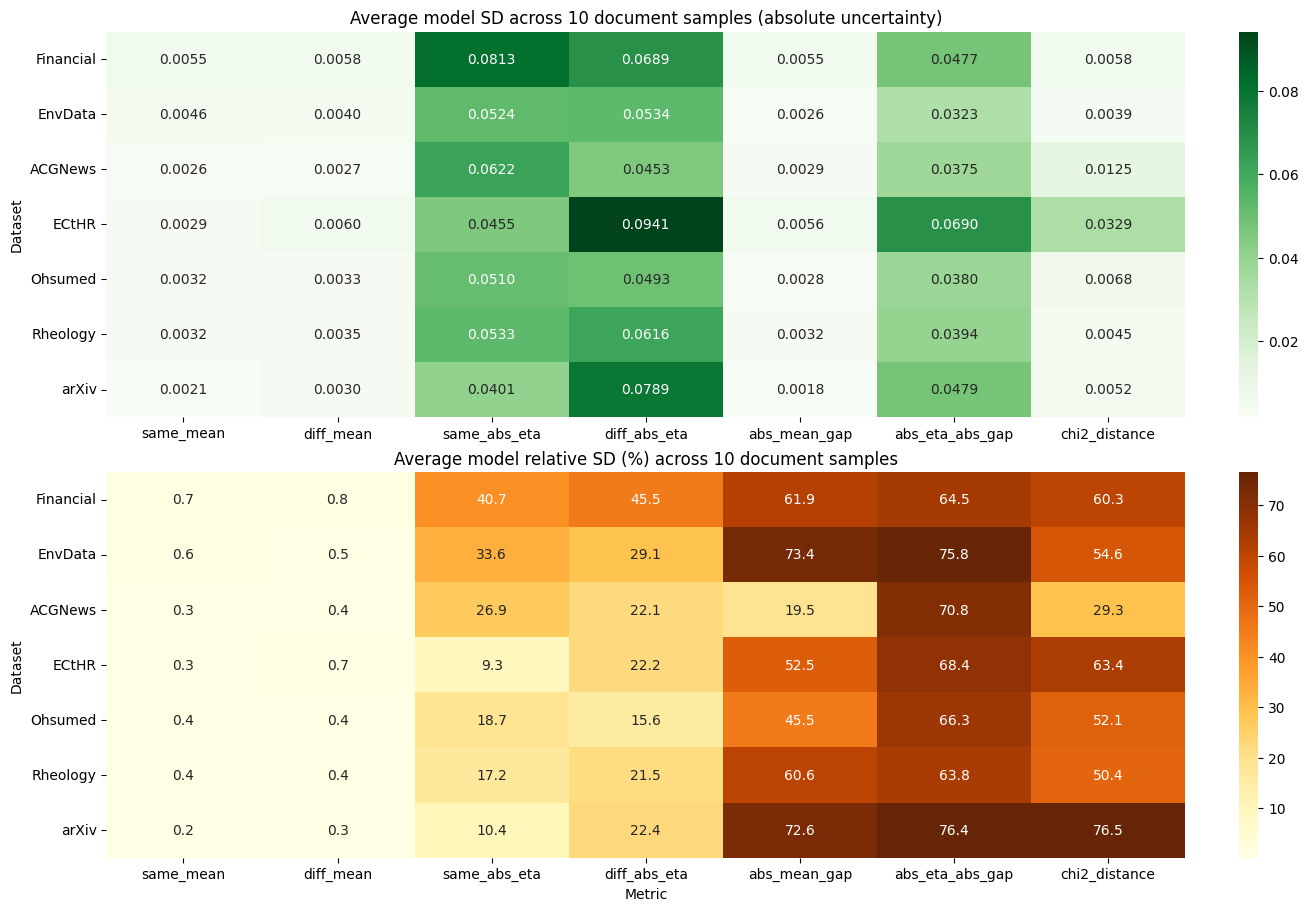

Uncertainty test confirmed complete: 7 datasets × 10 repetitions × 7 models = 490 rows.
Summary files saved to: /home/amyliu/Desktop/GR/Standardizing/results/rank_prediction_uncertainty10_label_first

Completion audit


,dataset,rows,expected_rows,models,repetitions,missing_values,duplicate_repetition_model_rows,complete
0,Financial,70,70,7,10,0,0,True
1,EnvData,70,70,7,10,0,0,True
2,ACGNews,70,70,7,10,0,0,True
3,ECtHR,70,70,7,10,0,0,True
4,Ohsumed,70,70,7,10,0,0,True
5,Rheology,70,70,7,10,0,0,True
6,arXiv,70,70,7,10,0,0,True



Key findings


,dataset,largest_absolute_variation_metric,largest_average_sd,largest_relative_variation_metric,largest_average_relative_sd_pct,smallest_absolute_variation_metric,smallest_average_sd
0,ACGNews,same_abs_eta,0.062197,abs_eta_abs_gap,70.824074,same_mean,0.002643
1,ECtHR,diff_abs_eta,0.094133,abs_eta_abs_gap,68.427691,same_mean,0.002941
2,EnvData,diff_abs_eta,0.053374,abs_eta_abs_gap,75.805917,abs_mean_gap,0.002559
3,Financial,same_abs_eta,0.081272,abs_eta_abs_gap,64.505000,abs_mean_gap,0.005486
4,Ohsumed,same_abs_eta,0.050973,abs_eta_abs_gap,66.302063,abs_mean_gap,0.002839
5,Rheology,diff_abs_eta,0.061613,abs_eta_abs_gap,63.841429,same_mean,0.003165
6,arXiv,diff_abs_eta,0.078927,chi2_distance,76.531699,abs_mean_gap,0.001797



Signed-gap direction stability


,dataset,signed_metric,sign_flip_models,models_tested
0,ACGNews,eta_abs_gap,7,7
1,ACGNews,eta_gap,7,7
2,ACGNews,mean_gap,0,7
3,ECtHR,eta_abs_gap,7,7
4,ECtHR,eta_gap,7,7
5,ECtHR,mean_gap,3,7
6,EnvData,eta_abs_gap,7,7
7,EnvData,eta_gap,7,7
8,EnvData,mean_gap,7,7
9,Financial,eta_abs_gap,5,7



Dataset × metric uncertainty summary


,dataset,metric,average_metric_value,average_sd,median_sd,maximum_sd,average_range,average_relative_sd_pct
0,ACGNews,abs_eta_abs_gap,0.052862,0.037485,0.034753,0.057354,0.113829,70.824074
1,ACGNews,abs_mean_gap,0.021240,0.002915,0.002749,0.004124,0.009613,19.471853
2,ACGNews,chi2_distance,0.061499,0.012526,0.012367,0.015565,0.042650,29.257849
3,ACGNews,diff_abs_eta,0.250540,0.045260,0.050713,0.059207,0.139842,22.139791
4,ACGNews,diff_mean,0.804073,0.002701,0.001831,0.005649,0.008400,0.354864
5,ACGNews,same_abs_eta,0.269656,0.062197,0.066272,0.079702,0.196419,26.908236
6,ACGNews,same_mean,0.825312,0.002643,0.002176,0.004419,0.008585,0.329357
7,ECtHR,abs_eta_abs_gap,0.105094,0.068966,0.068231,0.086671,0.215430,68.427691
8,ECtHR,abs_mean_gap,0.011404,0.005554,0.005948,0.008447,0.018381,52.488882
9,ECtHR,chi2_distance,0.054646,0.032883,0.033286,0.051122,0.108778,63.366687


In [26]:
# FINAL_UNCERTAINTY_SUMMARY
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# This cell is self-contained: it reads the completed experiment from disk.
summary_dir = BASE_DIR / "results" / "rank_prediction_uncertainty10_label_first"
results_path = summary_dir / "all_datasets_model_metrics_10runs.csv"
if not results_path.exists():
    raise FileNotFoundError(f"Completed uncertainty results not found: {results_path}")

uncertainty_results = pd.read_csv(results_path)
expected_datasets = list(UNCERTAINTY_DATASETS) if "UNCERTAINTY_DATASETS" in globals() else [
    "Financial", "EnvData", "ACGNews", "ECtHR", "Ohsumed", "Rheology", "arXiv"
]
expected_models = len(MODELS) if "MODELS" in globals() else 7
expected_repetitions = UNCERTAINTY_REPETITIONS if "UNCERTAINTY_REPETITIONS" in globals() else 10
expected_rows = expected_models * expected_repetitions

# 1. Completion and integrity audit.
audit_rows = []
for dataset in expected_datasets:
    part = uncertainty_results.loc[uncertainty_results["dataset"].eq(dataset)]
    audit_rows.append({
        "dataset": dataset,
        "rows": len(part),
        "expected_rows": expected_rows,
        "models": part["model"].nunique(),
        "repetitions": part["repetition"].nunique(),
        "missing_values": int(part.isna().sum().sum()),
        "duplicate_repetition_model_rows": int(part.duplicated(["repetition", "model"]).sum()),
        "complete": (
            len(part) == expected_rows
            and part["model"].nunique() == expected_models
            and part["repetition"].nunique() == expected_repetitions
            and not part.isna().any().any()
            and not part.duplicated(["repetition", "model"]).any()
        ),
    })
completion_audit = pd.DataFrame(audit_rows)
if not completion_audit["complete"].all():
    raise ValueError("The uncertainty experiment is incomplete. Inspect completion_audit.")

# 2. Model-level uncertainty across ten independent document samples.
metrics = [
    "same_mean", "diff_mean", "same_abs_eta", "diff_abs_eta",
    "abs_mean_gap", "abs_eta_abs_gap", "chi2_distance",
]
missing_metrics = sorted(set(metrics) - set(uncertainty_results.columns))
if missing_metrics:
    raise ValueError(f"Missing uncertainty metrics: {missing_metrics}")

metric_long = uncertainty_results.melt(
    id_vars=["dataset", "model", "repetition"],
    value_vars=metrics,
    var_name="metric",
    value_name="value",
)
model_metric_summary = (
    metric_long.groupby(["dataset", "model", "metric"], as_index=False)
    .agg(
        mean=("value", "mean"),
        sd=("value", "std"),
        minimum=("value", "min"),
        empirical_q025=("value", lambda x: x.quantile(0.025)),
        median=("value", "median"),
        empirical_q975=("value", lambda x: x.quantile(0.975)),
        maximum=("value", "max"),
    )
)
model_metric_summary["range"] = model_metric_summary["maximum"] - model_metric_summary["minimum"]
model_metric_summary["relative_sd_pct"] = np.where(
    model_metric_summary["mean"].abs() > 1e-12,
    100 * model_metric_summary["sd"] / model_metric_summary["mean"].abs(),
    np.nan,
)

# 3. Dataset-level summary: aggregate model-specific uncertainty, not raw model values.
dataset_metric_summary = (
    model_metric_summary.groupby(["dataset", "metric"], as_index=False)
    .agg(
        average_metric_value=("mean", "mean"),
        average_sd=("sd", "mean"),
        median_sd=("sd", "median"),
        maximum_sd=("sd", "max"),
        average_range=("range", "mean"),
        average_relative_sd_pct=("relative_sd_pct", "mean"),
    )
)

# 4. Signed-gap direction stability (diagnostic only; final metrics may use magnitudes).
signed_gap_columns = [column for column in ["mean_gap", "eta_gap", "eta_abs_gap"] if column in uncertainty_results]
direction_rows = []
for (dataset, model), rows in uncertainty_results.groupby(["dataset", "model"]):
    for metric in signed_gap_columns:
        values = rows[metric].dropna()
        positive = int(values.gt(0).sum())
        negative = int(values.lt(0).sum())
        zero = int(values.eq(0).sum())
        direction_rows.append({
            "dataset": dataset,
            "model": model,
            "signed_metric": metric,
            "positive_repetitions": positive,
            "negative_repetitions": negative,
            "zero_repetitions": zero,
            "direction_flipped": positive > 0 and negative > 0,
        })
direction_stability = pd.DataFrame(direction_rows)
dataset_direction_summary = (
    direction_stability.groupby(["dataset", "signed_metric"], as_index=False)
    .agg(
        sign_flip_models=("direction_flipped", "sum"),
        models_tested=("model", "nunique"),
    )
)

# 5. Concise findings for each dataset.
finding_rows = []
for dataset, rows in dataset_metric_summary.groupby("dataset", sort=False):
    absolute = rows.loc[rows["average_sd"].idxmax()]
    relative = rows.loc[rows["average_relative_sd_pct"].idxmax()]
    stable = rows.loc[rows["average_sd"].idxmin()]
    finding_rows.append({
        "dataset": dataset,
        "largest_absolute_variation_metric": absolute["metric"],
        "largest_average_sd": absolute["average_sd"],
        "largest_relative_variation_metric": relative["metric"],
        "largest_average_relative_sd_pct": relative["average_relative_sd_pct"],
        "smallest_absolute_variation_metric": stable["metric"],
        "smallest_average_sd": stable["average_sd"],
    })
key_findings = pd.DataFrame(finding_rows)

# 6. Save compact, reusable result tables.
completion_audit.to_csv(summary_dir / "uncertainty_completion_audit.csv", index=False)
model_metric_summary.to_csv(summary_dir / "uncertainty_model_metric_summary.csv", index=False)
dataset_metric_summary.to_csv(summary_dir / "uncertainty_dataset_metric_summary.csv", index=False)
direction_stability.to_csv(summary_dir / "uncertainty_direction_stability.csv", index=False)
key_findings.to_csv(summary_dir / "uncertainty_key_findings.csv", index=False)

# 7. Heatmaps: absolute and relative sampling sensitivity.
dataset_order = expected_datasets
metric_order = metrics
absolute_heatmap = dataset_metric_summary.pivot(index="dataset", columns="metric", values="average_sd").reindex(index=dataset_order, columns=metric_order)
relative_heatmap = dataset_metric_summary.pivot(index="dataset", columns="metric", values="average_relative_sd_pct").reindex(index=dataset_order, columns=metric_order)

fig, axes = plt.subplots(2, 1, figsize=(13, 9), constrained_layout=True)
sns.heatmap(absolute_heatmap, annot=True, fmt=".4f", cmap="Greens", ax=axes[0])
axes[0].set_title("Average model SD across 10 document samples (absolute uncertainty)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Dataset")
sns.heatmap(relative_heatmap, annot=True, fmt=".1f", cmap="YlOrBr", ax=axes[1])
axes[1].set_title("Average model relative SD (%) across 10 document samples")
axes[1].set_xlabel("Metric")
axes[1].set_ylabel("Dataset")
figure_path = summary_dir / "uncertainty_metric_stability_heatmaps.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Uncertainty test confirmed complete: 7 datasets × 10 repetitions × 7 models = 490 rows.")
print("Summary files saved to:", summary_dir)
print("\nCompletion audit")
display(completion_audit)
print("\nKey findings")
display(key_findings)
print("\nSigned-gap direction stability")
display(dataset_direction_summary)
print("\nDataset × metric uncertainty summary")
display(dataset_metric_summary)


### Pearson Correlation ##

### Pearson correlation with standardized fine-tuning results

This section links the completed standardized rank-prediction experiment to the completed standardized five-fold fine-tuning results.

**Target variables**

- `macro_f1_mean`: five-fold mean Macro F1 for each dataset–model combination.
- `micro_f1_mean`: five-fold mean Micro F1 for each dataset–model combination.

**Prediction variables**

All seven currently reported metrics are included:

- Same-label cosine mean
- Different-label cosine mean
- Same-label absolute Eta
- Different-label absolute Eta
- Absolute cosine-mean gap
- Absolute absolute-Eta gap
- Chi-square distance

Three complementary Pearson analyses are reported:

1. **Primary correlation:** average each prediction metric over the ten document samples, then correlate the seven model values with the seven five-fold F1 values within each dataset (`n=7`).
2. **Repetition-level uncertainty:** calculate Pearson correlation separately in every document-sampling repetition, then report its ten-run mean, SD, minimum, maximum, and sign-flip count.
3. **Pooled repeated-observation correlation:** use all 70 rows within a dataset only as a descriptive sensitivity analysis. Its p-value is deliberately omitted because the same seven F1 targets are repeated ten times and the 70 rows are not independent.

The primary per-dataset coefficient is comparable in structure to a seven-model correlation table. Because each coefficient uses only seven models and many metric–target combinations are tested, the coefficient magnitude, ten-run stability, and adjusted p-value must be considered together. Pearson measures linear association; it does not measure ranking agreement or causation.


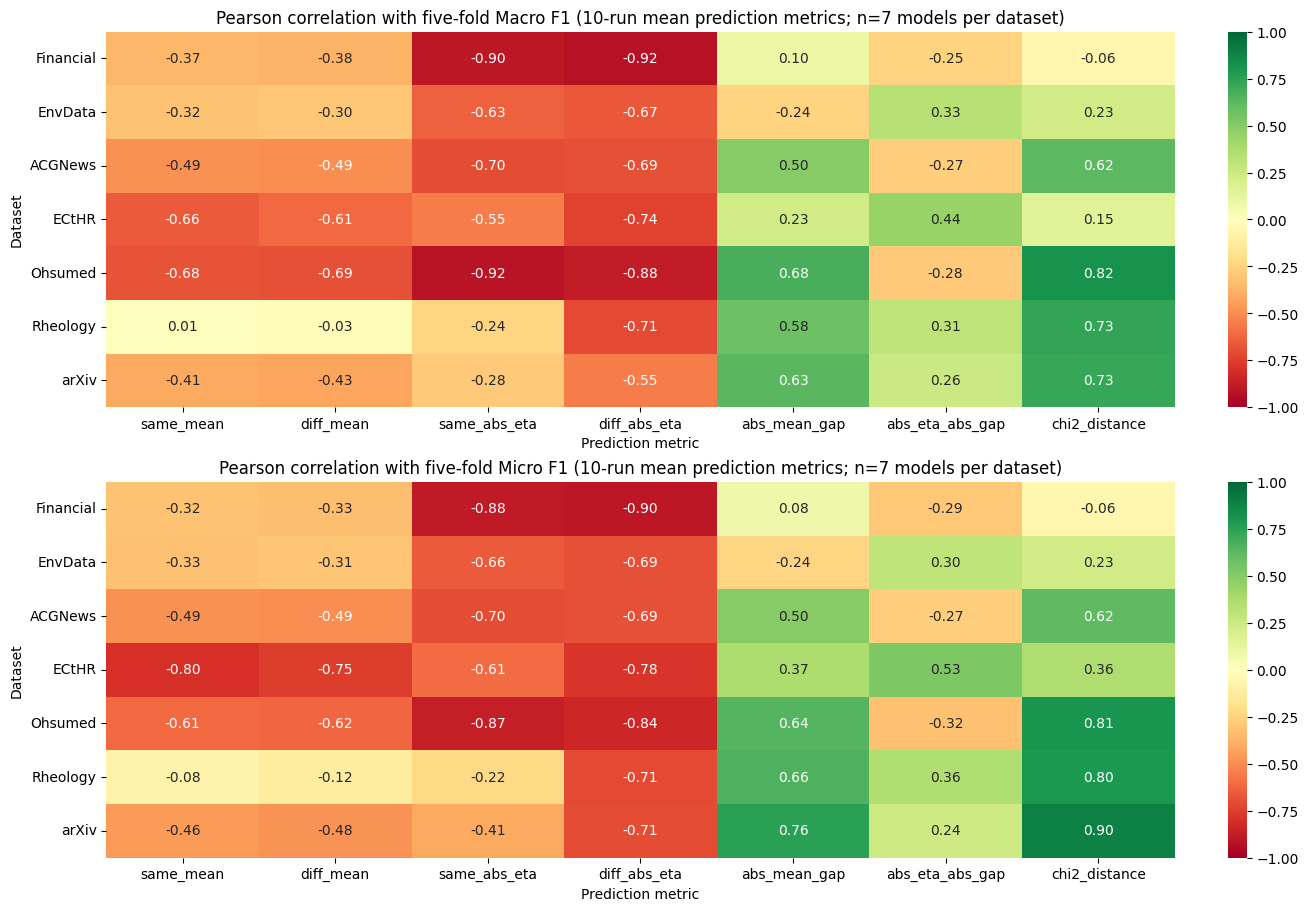

Pearson analysis complete.
Merged observations: 490
Independent dataset-model targets: 49
Saved results to: /home/amyliu/Desktop/GR/Standardizing/results/standardized_pearson_correlation

Merge audit


,dataset,rows,models,repetitions,missing_values,complete
0,Financial,70,7,10,0,True
1,EnvData,70,7,10,0,True
2,ACGNews,70,7,10,0,True
3,ECtHR,70,7,10,0,True
4,Ohsumed,70,7,10,0,True
5,Rheology,70,7,10,0,True
6,arXiv,70,7,10,0,True



Primary Pearson correlation with Macro F1


metric,same_mean,diff_mean,same_abs_eta,diff_abs_eta,abs_mean_gap,abs_eta_abs_gap,chi2_distance
dataset,,,,,,,
Financial,-0.366,-0.382,-0.900,-0.924,0.098,-0.250,-0.058
EnvData,-0.318,-0.304,-0.634,-0.667,-0.244,0.331,0.234
ACGNews,-0.490,-0.495,-0.705,-0.692,0.498,-0.267,0.618
ECtHR,-0.661,-0.613,-0.550,-0.738,0.234,0.444,0.149
Ohsumed,-0.682,-0.690,-0.916,-0.877,0.676,-0.285,0.819
Rheology,0.012,-0.031,-0.239,-0.715,0.576,0.306,0.729
arXiv,-0.411,-0.428,-0.284,-0.547,0.628,0.257,0.726



Primary Pearson correlation with Micro F1


metric,same_mean,diff_mean,same_abs_eta,diff_abs_eta,abs_mean_gap,abs_eta_abs_gap,chi2_distance
dataset,,,,,,,
Financial,-0.316,-0.329,-0.883,-0.901,0.081,-0.292,-0.060
EnvData,-0.328,-0.312,-0.663,-0.695,-0.240,0.304,0.231
ACGNews,-0.490,-0.494,-0.704,-0.691,0.497,-0.268,0.617
ECtHR,-0.803,-0.753,-0.606,-0.783,0.370,0.526,0.361
Ohsumed,-0.611,-0.621,-0.874,-0.836,0.644,-0.321,0.809
Rheology,-0.081,-0.125,-0.220,-0.714,0.660,0.358,0.797
arXiv,-0.459,-0.483,-0.406,-0.706,0.757,0.242,0.896



Correlation uncertainty across 10 document samples


,dataset,target,metric,pearson_mean,pearson_sd,pearson_min,pearson_max,positive_repetitions,negative_repetitions,direction_flipped
0,ACGNews,macro_f1_mean,abs_eta_abs_gap,-0.050683,0.395107,-0.566507,0.492323,5,5,True
1,ACGNews,macro_f1_mean,abs_mean_gap,0.488252,0.059999,0.365896,0.592442,10,0,False
2,ACGNews,macro_f1_mean,chi2_distance,0.595397,0.083477,0.448064,0.707879,10,0,False
3,ACGNews,macro_f1_mean,diff_abs_eta,-0.600904,0.168216,-0.878526,-0.309389,0,10,False
4,ACGNews,macro_f1_mean,diff_mean,-0.494271,0.012520,-0.509336,-0.474068,0,10,False
...,...,...,...,...,...,...,...,...,...,...
93,arXiv,micro_f1_mean,chi2_distance,0.612718,0.348250,-0.269894,0.903592,9,1,True
94,arXiv,micro_f1_mean,diff_abs_eta,-0.546461,0.166799,-0.762311,-0.244478,0,10,False
95,arXiv,micro_f1_mean,diff_mean,-0.481363,0.037636,-0.544282,-0.441640,0,10,False
96,arXiv,micro_f1_mean,same_abs_eta,-0.344364,0.141885,-0.535120,-0.136484,0,10,False


In [27]:
# STANDARDIZED_PEARSON_CORRELATION
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from IPython.display import display

analysis_base = BASE_DIR if "BASE_DIR" in globals() else Path.cwd()
if (analysis_base / "Standardizing").is_dir():
    analysis_base = analysis_base / "Standardizing"

finetuning_path = analysis_base / "results" / "finetuning_8epochs_5fold" / "model_summary.csv"
prediction_path = analysis_base / "results" / "rank_prediction_uncertainty10_label_first" / "all_datasets_model_metrics_10runs.csv"
pearson_output_dir = analysis_base / "results" / "standardized_pearson_correlation"
pearson_output_dir.mkdir(parents=True, exist_ok=True)

if not finetuning_path.exists():
    raise FileNotFoundError(f"Fine-tuning summary not found: {finetuning_path}")
if not prediction_path.exists():
    raise FileNotFoundError(f"Prediction results not found: {prediction_path}")

f1_results = pd.read_csv(finetuning_path)
prediction_results = pd.read_csv(prediction_path)

metrics = [
    "same_mean", "diff_mean", "same_abs_eta", "diff_abs_eta",
    "abs_mean_gap", "abs_eta_abs_gap", "chi2_distance",
]
targets = ["macro_f1_mean", "micro_f1_mean"]
dataset_order = ["Financial", "EnvData", "ACGNews", "ECtHR", "Ohsumed", "Rheology", "arXiv"]

required_f1 = {"dataset", "model", *targets}
required_prediction = {"dataset", "model", "repetition", *metrics}
if missing := required_f1 - set(f1_results.columns):
    raise ValueError(f"Missing fine-tuning columns: {sorted(missing)}")
if missing := required_prediction - set(prediction_results.columns):
    raise ValueError(f"Missing prediction columns: {sorted(missing)}")

# Enforce one F1 target per dataset-model and a complete 10 × 7 prediction design.
f1_targets = f1_results[["dataset", "model", *targets]].copy()
if f1_targets.duplicated(["dataset", "model"]).any():
    raise ValueError("Fine-tuning summary has duplicate dataset-model rows.")

merged_all = prediction_results.merge(
    f1_targets,
    on=["dataset", "model"],
    how="left",
    validate="many_to_one",
    indicator=True,
)
if not merged_all["_merge"].eq("both").all():
    unmatched = merged_all.loc[merged_all["_merge"].ne("both"), ["dataset", "model"]].drop_duplicates()
    raise ValueError(f"Unmatched prediction rows:\n{unmatched}")
merged_all = merged_all.drop(columns="_merge")

merge_audit = (
    merged_all.groupby("dataset", as_index=False)
    .agg(
        rows=("model", "size"),
        models=("model", "nunique"),
        repetitions=("repetition", "nunique"),
        missing_values=("macro_f1_mean", lambda x: int(x.isna().sum())),
    )
    .set_index("dataset")
    .reindex(dataset_order)
    .reset_index()
)
merge_audit["complete"] = (
    merge_audit["rows"].eq(70)
    & merge_audit["models"].eq(7)
    & merge_audit["repetitions"].eq(10)
    & merge_audit["missing_values"].eq(0)
)
if not merge_audit["complete"].all():
    raise ValueError("Merged correlation data are incomplete; inspect merge_audit.")


def safe_pearson(x, y):
    """Return Pearson r and p; reject missing, constant, or undersized inputs."""
    pair = pd.DataFrame({"x": x, "y": y}).dropna()
    if len(pair) < 3 or pair["x"].nunique() < 2 or pair["y"].nunique() < 2:
        return np.nan, np.nan, len(pair)
    result = pearsonr(pair["x"], pair["y"])
    return float(result.statistic), float(result.pvalue), len(pair)


def benjamini_hochberg(p_values):
    """Benjamini-Hochberg false-discovery-rate adjustment."""
    values = np.asarray(p_values, dtype=float)
    adjusted = np.full(values.shape, np.nan)
    valid = np.flatnonzero(np.isfinite(values))
    if len(valid) == 0:
        return adjusted
    order = valid[np.argsort(values[valid])]
    ranked = values[order] * len(order) / np.arange(1, len(order) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    adjusted[order] = np.minimum(ranked, 1.0)
    return adjusted

# Primary analysis: ten-run mean prediction metrics, seven independent models per dataset.
model_mean_metrics = (
    merged_all.groupby(["dataset", "model"], as_index=False)[metrics].mean()
    .merge(f1_targets, on=["dataset", "model"], validate="one_to_one")
)
primary_rows = []
for dataset in dataset_order:
    rows = model_mean_metrics.loc[model_mean_metrics["dataset"].eq(dataset)]
    for target in targets:
        for metric in metrics:
            r, p_value, n = safe_pearson(rows[metric], rows[target])
            primary_rows.append({
                "dataset": dataset,
                "target": target,
                "metric": metric,
                "pearson_r": r,
                "p_value": p_value,
                "n_models": n,
            })
primary_pearson = pd.DataFrame(primary_rows)
primary_pearson["p_fdr_within_target"] = (
    primary_pearson.groupby("target")["p_value"].transform(benjamini_hochberg)
)

# Repetition-level analysis: 10 Pearson coefficients per dataset-metric-target.
repetition_rows = []
for (dataset, repetition), rows in merged_all.groupby(["dataset", "repetition"]):
    for target in targets:
        for metric in metrics:
            r, p_value, n = safe_pearson(rows[metric], rows[target])
            repetition_rows.append({
                "dataset": dataset,
                "repetition": int(repetition),
                "target": target,
                "metric": metric,
                "pearson_r": r,
                "p_value": p_value,
                "n_models": n,
            })
pearson_per_repetition = pd.DataFrame(repetition_rows)
pearson_uncertainty = (
    pearson_per_repetition.groupby(["dataset", "target", "metric"], as_index=False)
    .agg(
        pearson_mean=("pearson_r", "mean"),
        pearson_sd=("pearson_r", "std"),
        pearson_min=("pearson_r", "min"),
        pearson_max=("pearson_r", "max"),
        positive_repetitions=("pearson_r", lambda x: int(x.gt(0).sum())),
        negative_repetitions=("pearson_r", lambda x: int(x.lt(0).sum())),
    )
)
pearson_uncertainty["direction_flipped"] = (
    pearson_uncertainty["positive_repetitions"].gt(0)
    & pearson_uncertainty["negative_repetitions"].gt(0)
)

# Descriptive pooled coefficient using all 70 repeated rows; no inferential p-value.
pooled_rows = []
for dataset in dataset_order:
    rows = merged_all.loc[merged_all["dataset"].eq(dataset)]
    for target in targets:
        for metric in metrics:
            r, _, n = safe_pearson(rows[metric], rows[target])
            pooled_rows.append({
                "dataset": dataset,
                "target": target,
                "metric": metric,
                "pooled_descriptive_r": r,
                "n_repeated_rows": n,
                "p_value": np.nan,
            })
pooled_descriptive = pd.DataFrame(pooled_rows)

# Combine the primary coefficient with its sampling uncertainty across repetitions.
pearson_summary = (
    primary_pearson.merge(
        pearson_uncertainty,
        on=["dataset", "target", "metric"],
        validate="one_to_one",
    )
    .merge(
        pooled_descriptive,
        on=["dataset", "target", "metric"],
        validate="one_to_one",
        suffixes=("", "_pooled"),
    )
)

# Riyadi-style wide tables: one row per dataset and one column per metric.
macro_table = primary_pearson.loc[primary_pearson["target"].eq("macro_f1_mean")].pivot(
    index="dataset", columns="metric", values="pearson_r"
).reindex(index=dataset_order, columns=metrics)
micro_table = primary_pearson.loc[primary_pearson["target"].eq("micro_f1_mean")].pivot(
    index="dataset", columns="metric", values="pearson_r"
).reindex(index=dataset_order, columns=metrics)

# Save every analysis table.
merge_audit.to_csv(pearson_output_dir / "merge_audit.csv", index=False)
model_mean_metrics.to_csv(pearson_output_dir / "model_metrics_10run_means_with_f1.csv", index=False)
primary_pearson.to_csv(pearson_output_dir / "pearson_primary_10run_means.csv", index=False)
pearson_per_repetition.to_csv(pearson_output_dir / "pearson_per_repetition.csv", index=False)
pearson_uncertainty.to_csv(pearson_output_dir / "pearson_repetition_uncertainty.csv", index=False)
pooled_descriptive.to_csv(pearson_output_dir / "pearson_pooled_descriptive.csv", index=False)
pearson_summary.to_csv(pearson_output_dir / "pearson_complete_summary.csv", index=False)
macro_table.to_csv(pearson_output_dir / "pearson_macro_f1_table.csv")
micro_table.to_csv(pearson_output_dir / "pearson_micro_f1_table.csv")

# Correlation heatmaps for the primary analysis.
fig, axes = plt.subplots(2, 1, figsize=(13, 9), constrained_layout=True)
for ax, table, title in [
    (axes[0], macro_table, "Pearson correlation with five-fold Macro F1"),
    (axes[1], micro_table, "Pearson correlation with five-fold Micro F1"),
]:
    sns.heatmap(table, annot=True, fmt=".2f", cmap="RdYlGn", center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title(title + " (10-run mean prediction metrics; n=7 models per dataset)")
    ax.set_xlabel("Prediction metric")
    ax.set_ylabel("Dataset")
figure_path = pearson_output_dir / "pearson_f1_heatmaps.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Pearson analysis complete.")
print("Merged observations:", len(merged_all))
print("Independent dataset-model targets:", len(model_mean_metrics))
print("Saved results to:", pearson_output_dir)
print("\nMerge audit")
display(merge_audit)
print("\nPrimary Pearson correlation with Macro F1")
display(macro_table.round(3))
print("\nPrimary Pearson correlation with Micro F1")
display(micro_table.round(3))
print("\nCorrelation uncertainty across 10 document samples")
display(pearson_uncertainty)


Table 19-style signed Spearman summary for the proposed metrics

Each coefficient compares the ranking induced by a ten-run mean prediction metric with the ranking induced by five-fold F1 across the seven candidate models. Direction is preserved. Each table includes the arithmetic mean of the signed coefficients across the seven datasets.


In [28]:
# PROPOSED_TABLE19_SPEARMAN_SUMMARY: signed Spearman correlations only
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from IPython.display import display

spearman_base = BASE_DIR if "BASE_DIR" in globals() else Path.cwd()
if (spearman_base / "Standardizing").is_dir():
    spearman_base = spearman_base / "Standardizing"

proposed_metric_path = (
    spearman_base
    / "results"
    / "standardized_pearson_correlation"
    / "model_metrics_10run_means_with_f1.csv"
)
proposed_spearman_output_dir = (
    spearman_base / "results" / "standardized_spearman_correlation"
)
proposed_spearman_output_dir.mkdir(parents=True, exist_ok=True)

proposed_spearman_data = pd.read_csv(
    proposed_metric_path
)
proposed_metrics = [
    "same_mean",
    "diff_mean",
    "same_abs_eta",
    "diff_abs_eta",
    "abs_mean_gap",
    "abs_eta_abs_gap",
    "chi2_distance",
]
proposed_targets = [
    "micro_f1_mean",
    "macro_f1_mean",
]
proposed_dataset_order = [
    "Financial",
    "EnvData",
    "ACGNews",
    "ECtHR",
    "Ohsumed",
    "Rheology",
    "arXiv",
]
required_columns = {
    "dataset",
    "model",
    *proposed_metrics,
    *proposed_targets,
}
missing_columns = required_columns - set(proposed_spearman_data.columns)
if missing_columns:
    raise ValueError(
        f"Missing columns: {sorted(missing_columns)}"
    )

proposed_spearman_rows = []
for dataset_name in proposed_dataset_order:
    group = proposed_spearman_data.loc[
        proposed_spearman_data["dataset"].eq(dataset_name)
    ]
    if len(group) != 7 or group["model"].nunique() != 7:
        raise ValueError(
            f"{dataset_name} must contain exactly seven unique models."
        )
    for target in proposed_targets:
        for metric in proposed_metrics:
            result = spearmanr(group[metric], group[target])
            proposed_spearman_rows.append({
                "dataset": dataset_name,
                "target": target,
                "metric": metric,
                "spearman_signed": float(result.statistic),
                "p_value": float(result.pvalue),
                "n_models": len(group),
            })

proposed_spearman_correlations = pd.DataFrame(
    proposed_spearman_rows
)
proposed_spearman_correlations.to_csv(
    proposed_spearman_output_dir / "spearman_correlations.csv",
    index=False,
)

proposed_spearman_tables = {}
for target in proposed_targets:
    table = (
        proposed_spearman_correlations.loc[
            proposed_spearman_correlations["target"].eq(target)
        ]
        .pivot(
            index="dataset",
            columns="metric",
            values="spearman_signed",
        )
        .reindex(
            index=proposed_dataset_order,
            columns=proposed_metrics,
        )
    )
    table.loc["Average"] = table.mean(axis=0)
    table.index.name = "Dataset"
    proposed_spearman_tables[target] = table
    table.to_csv(
        proposed_spearman_output_dir
        / f"table19_style_spearman_{target}_signed.csv"
    )

print("Proposed metrics: signed Spearman correlations with Micro-F1")
display(proposed_spearman_tables["micro_f1_mean"].round(3))
print("Proposed metrics: signed Spearman correlations with Macro-F1")
display(proposed_spearman_tables["macro_f1_mean"].round(3))
print("Saved to:", proposed_spearman_output_dir)


Proposed metrics: signed Spearman correlations with Micro-F1


metric,same_mean,diff_mean,same_abs_eta,diff_abs_eta,abs_mean_gap,abs_eta_abs_gap,chi2_distance
Dataset,,,,,,,
Financial,-0.286,-0.286,-0.464,-0.464,-0.143,-0.857,0.071
EnvData,-0.357,-0.357,-0.571,-0.750,-0.357,0.071,0.179
ACGNews,-0.607,-0.607,-0.821,-0.929,0.607,-0.179,0.786
ECtHR,-0.929,-0.786,-0.357,-0.857,0.214,0.571,0.286
Ohsumed,-0.786,-0.786,-0.929,-0.964,0.643,-0.071,0.786
Rheology,-0.286,-0.286,-0.214,-0.571,0.786,0.643,0.929
arXiv,-0.536,-0.571,-0.643,-0.857,0.786,0.107,0.964
Average,-0.541,-0.526,-0.571,-0.770,0.362,0.041,0.571


Proposed metrics: signed Spearman correlations with Macro-F1


metric,same_mean,diff_mean,same_abs_eta,diff_abs_eta,abs_mean_gap,abs_eta_abs_gap,chi2_distance
Dataset,,,,,,,
Financial,-0.464,-0.464,-0.571,-0.571,0.000,-0.679,0.107
EnvData,-0.357,-0.357,-0.571,-0.750,-0.357,0.071,0.179
ACGNews,-0.607,-0.607,-0.821,-0.929,0.607,-0.179,0.786
ECtHR,-0.536,-0.321,-0.036,-0.607,0.179,0.643,0.107
Ohsumed,-0.750,-0.750,-0.964,-1.000,0.679,-0.179,0.893
Rheology,-0.286,-0.286,-0.214,-0.571,0.786,0.643,0.929
arXiv,-0.607,-0.643,-0.357,-0.571,0.714,0.036,0.750
Average,-0.515,-0.490,-0.505,-0.714,0.372,0.051,0.536


Saved to: /home/amyliu/Desktop/GR/Standardizing/results/standardized_spearman_correlation


### Diagram Results

<b>uncertainty </b>

#### Standardized ten-run uncertainty diagrams

The figures below use the current standardized ten-repetition metric file and the standardized five-fold F1 summary. They measure sampling uncertainty at the individual-metric, model-pair, and ranking-correlation levels. Because coefficients have not yet been re-selected from the standardized results, this section does not reuse the earlier grid-search weights; doing so would mix two experimental settings.


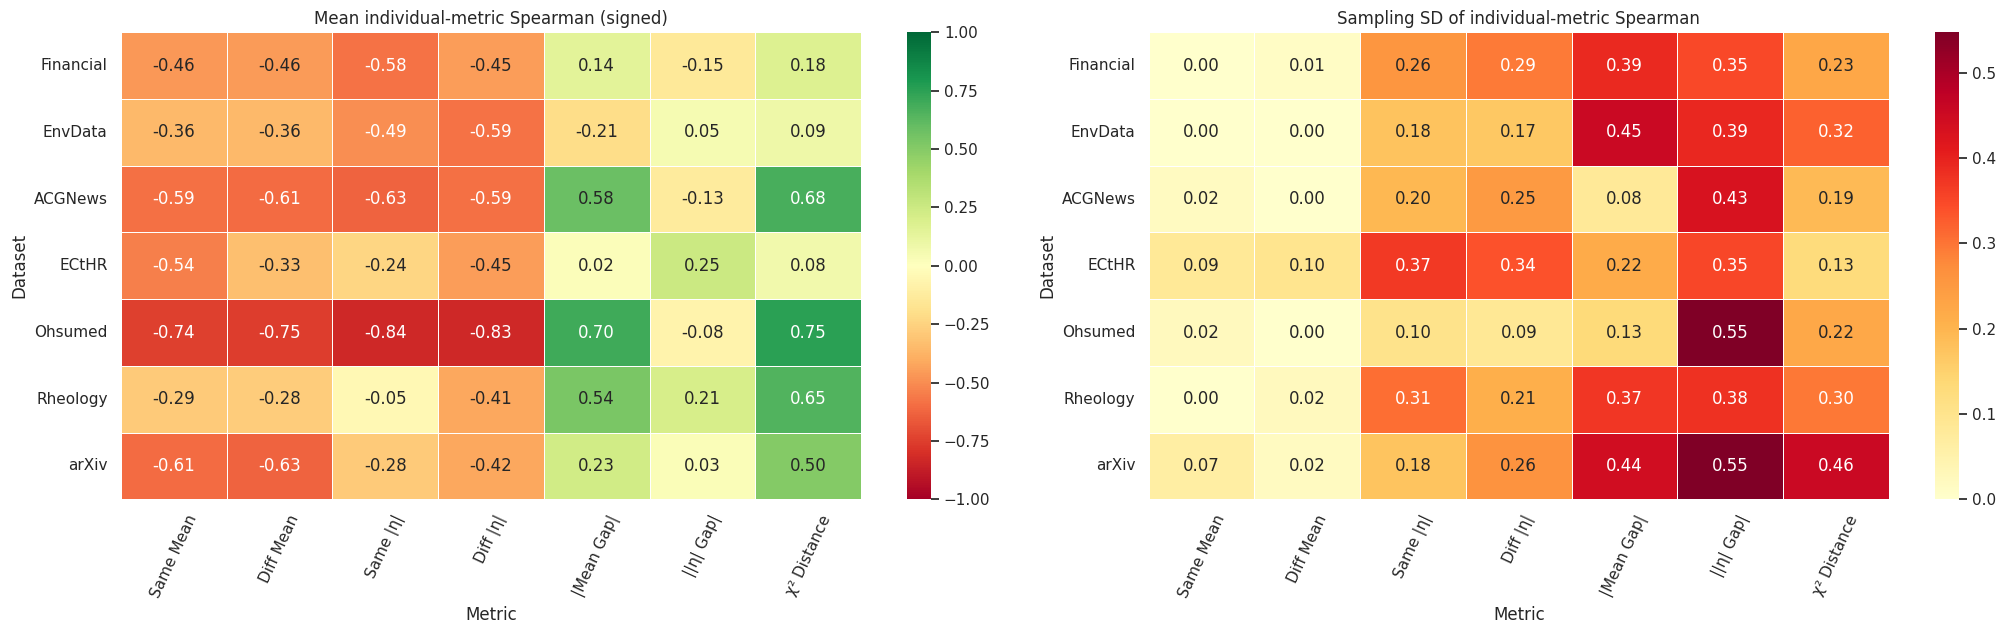

Saved: /home/amyliu/Desktop/GR/Standardizing/results/rank_prediction_uncertainty10_label_first/diagram_results/uncertainty/01_single_metric_spearman_stability.png


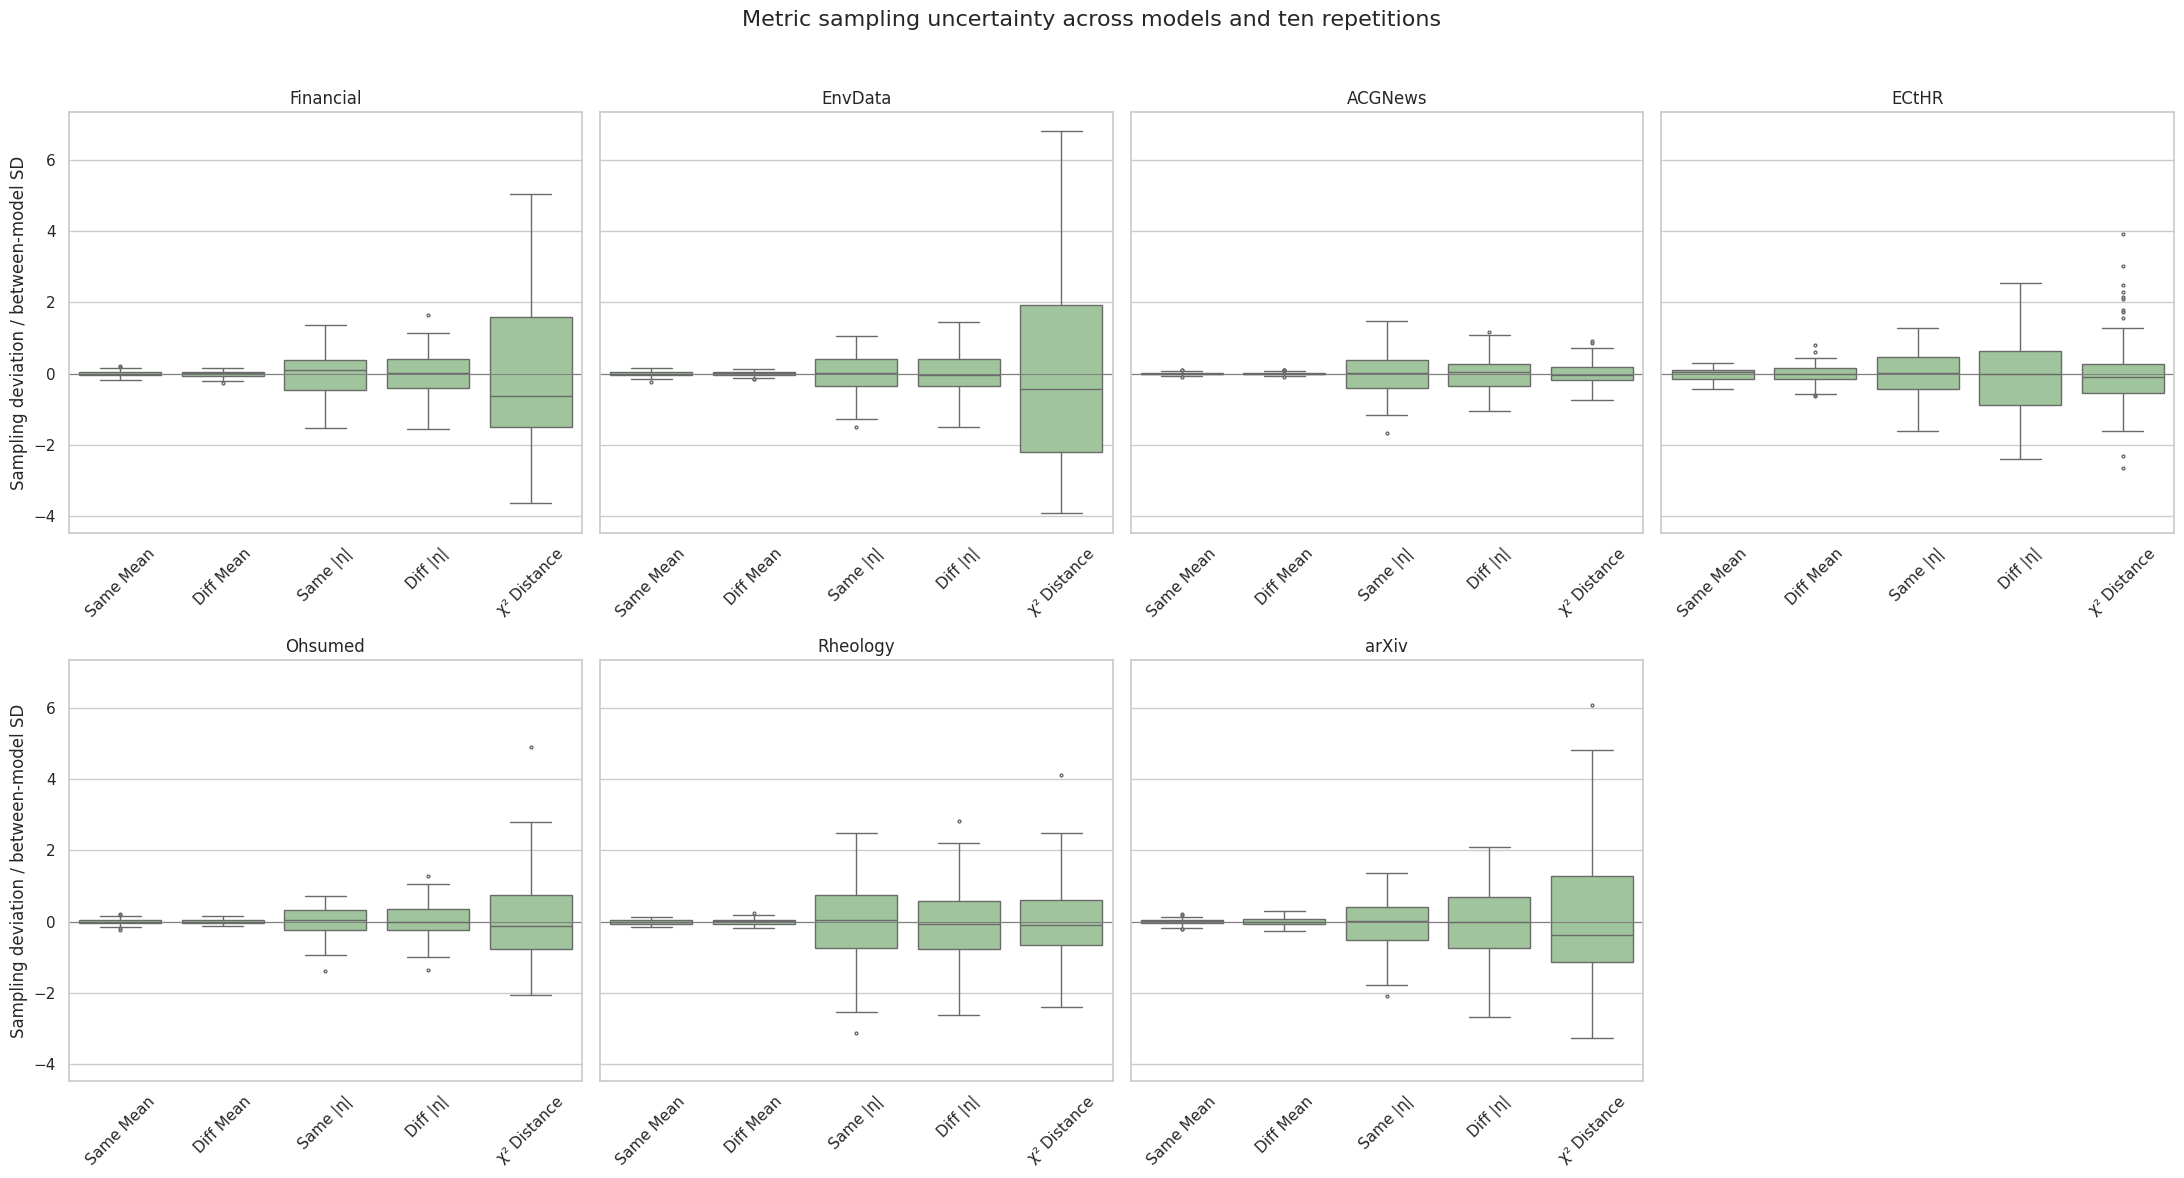

Saved: /home/amyliu/Desktop/GR/Standardizing/results/rank_prediction_uncertainty10_label_first/diagram_results/uncertainty/02_metric_sampling_deviations.png


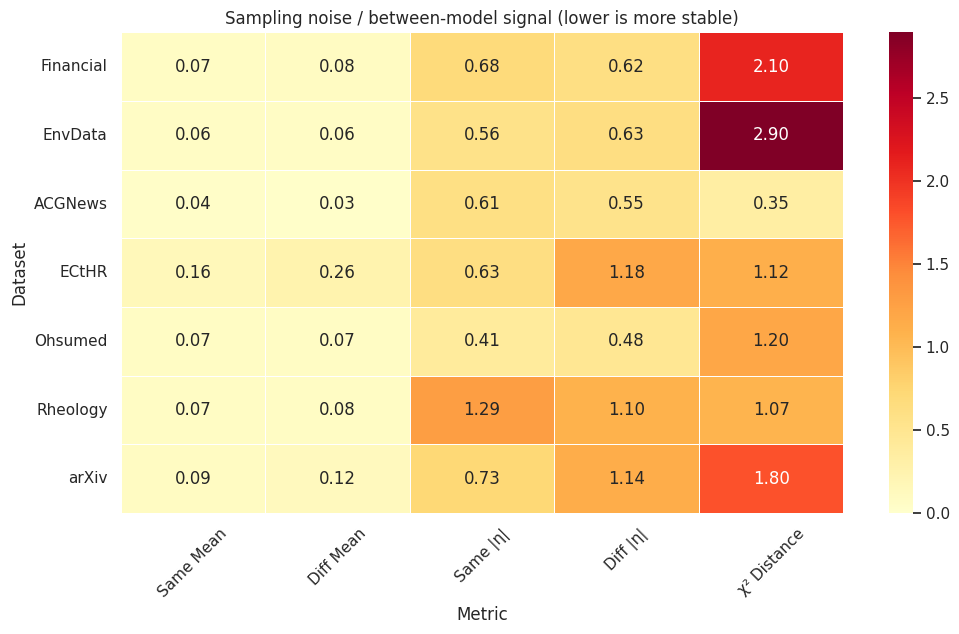

Saved: /home/amyliu/Desktop/GR/Standardizing/results/rank_prediction_uncertainty10_label_first/diagram_results/uncertainty/03_metric_noise_to_signal.png


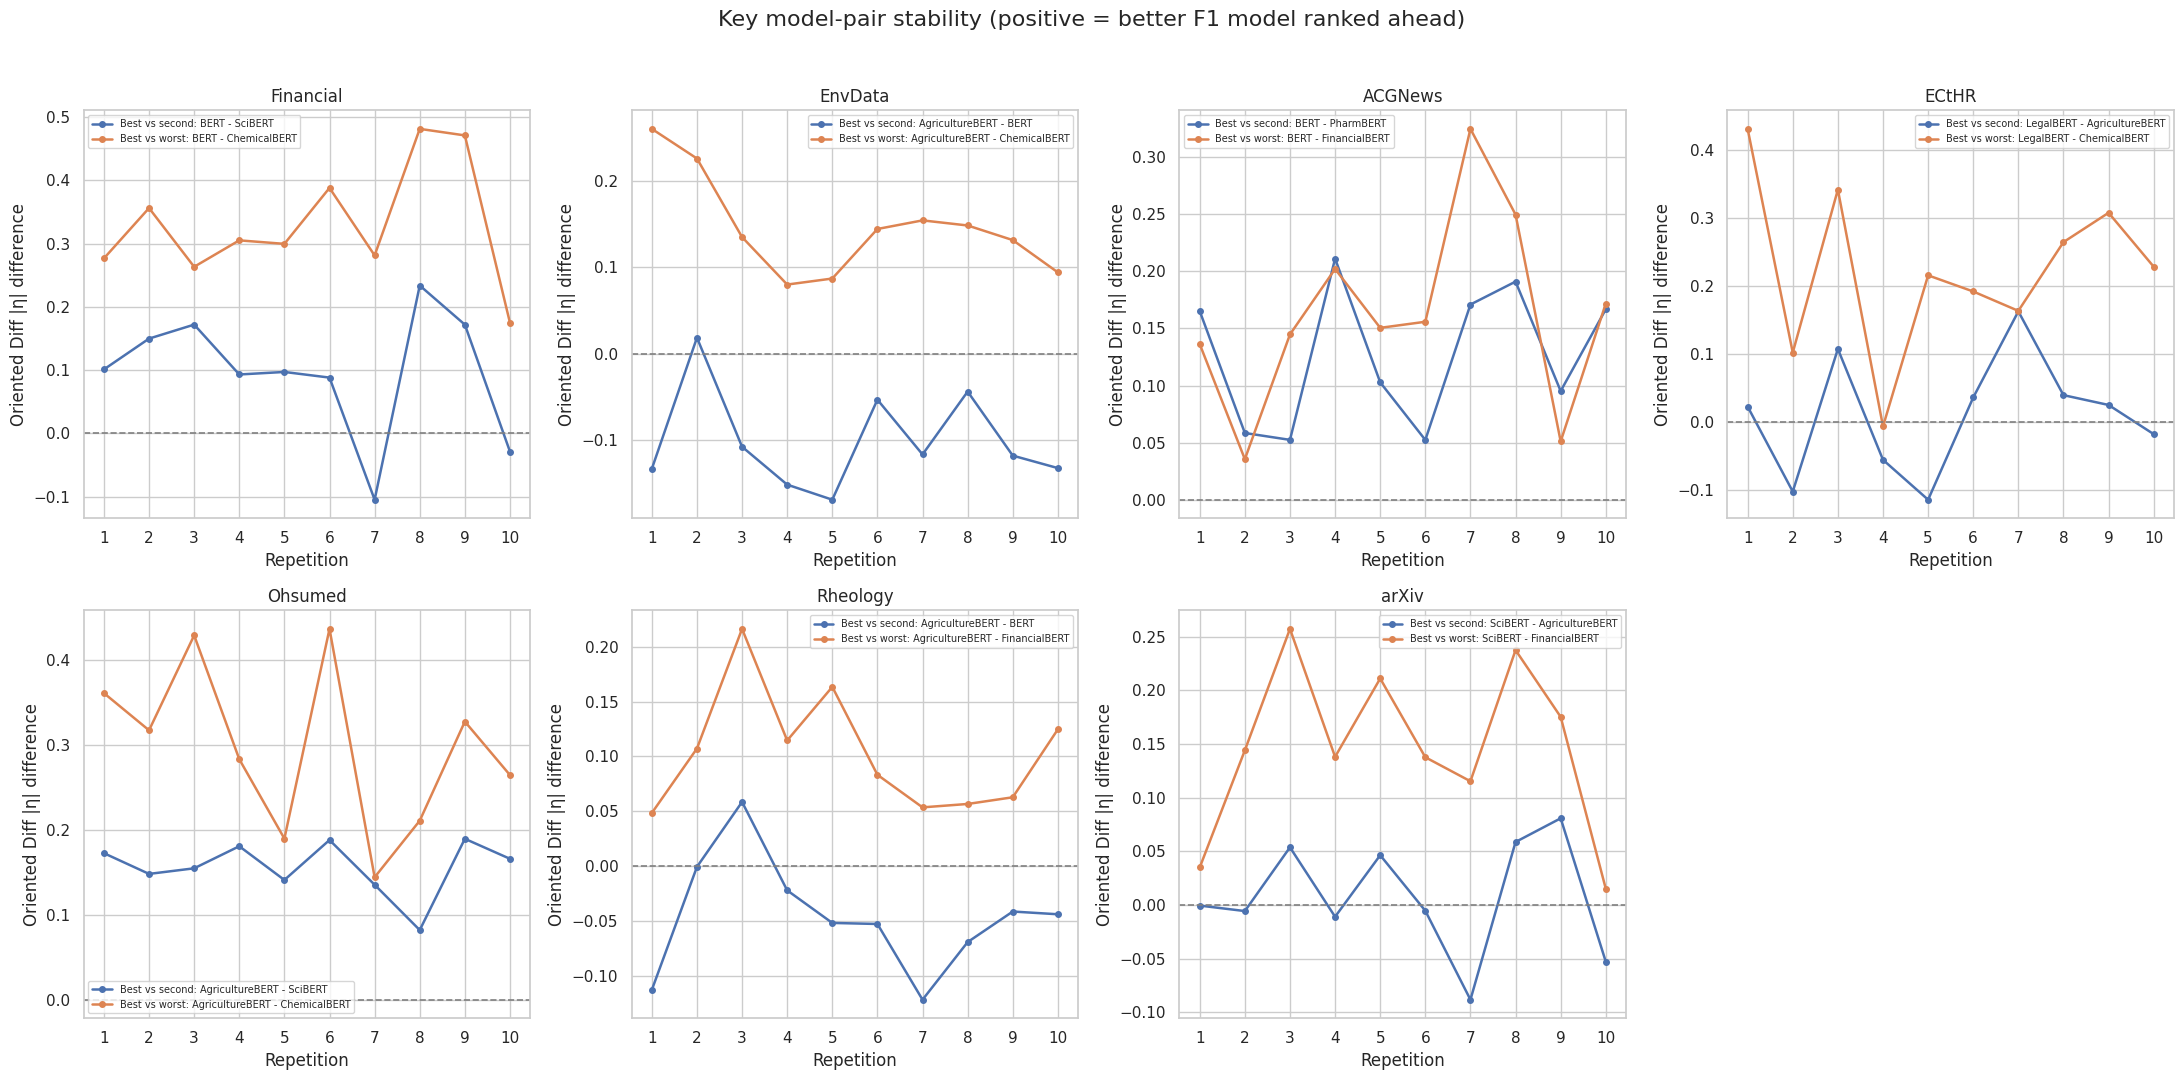

Saved: /home/amyliu/Desktop/GR/Standardizing/results/rank_prediction_uncertainty10_label_first/diagram_results/uncertainty/04_key_model_pair_stability.png


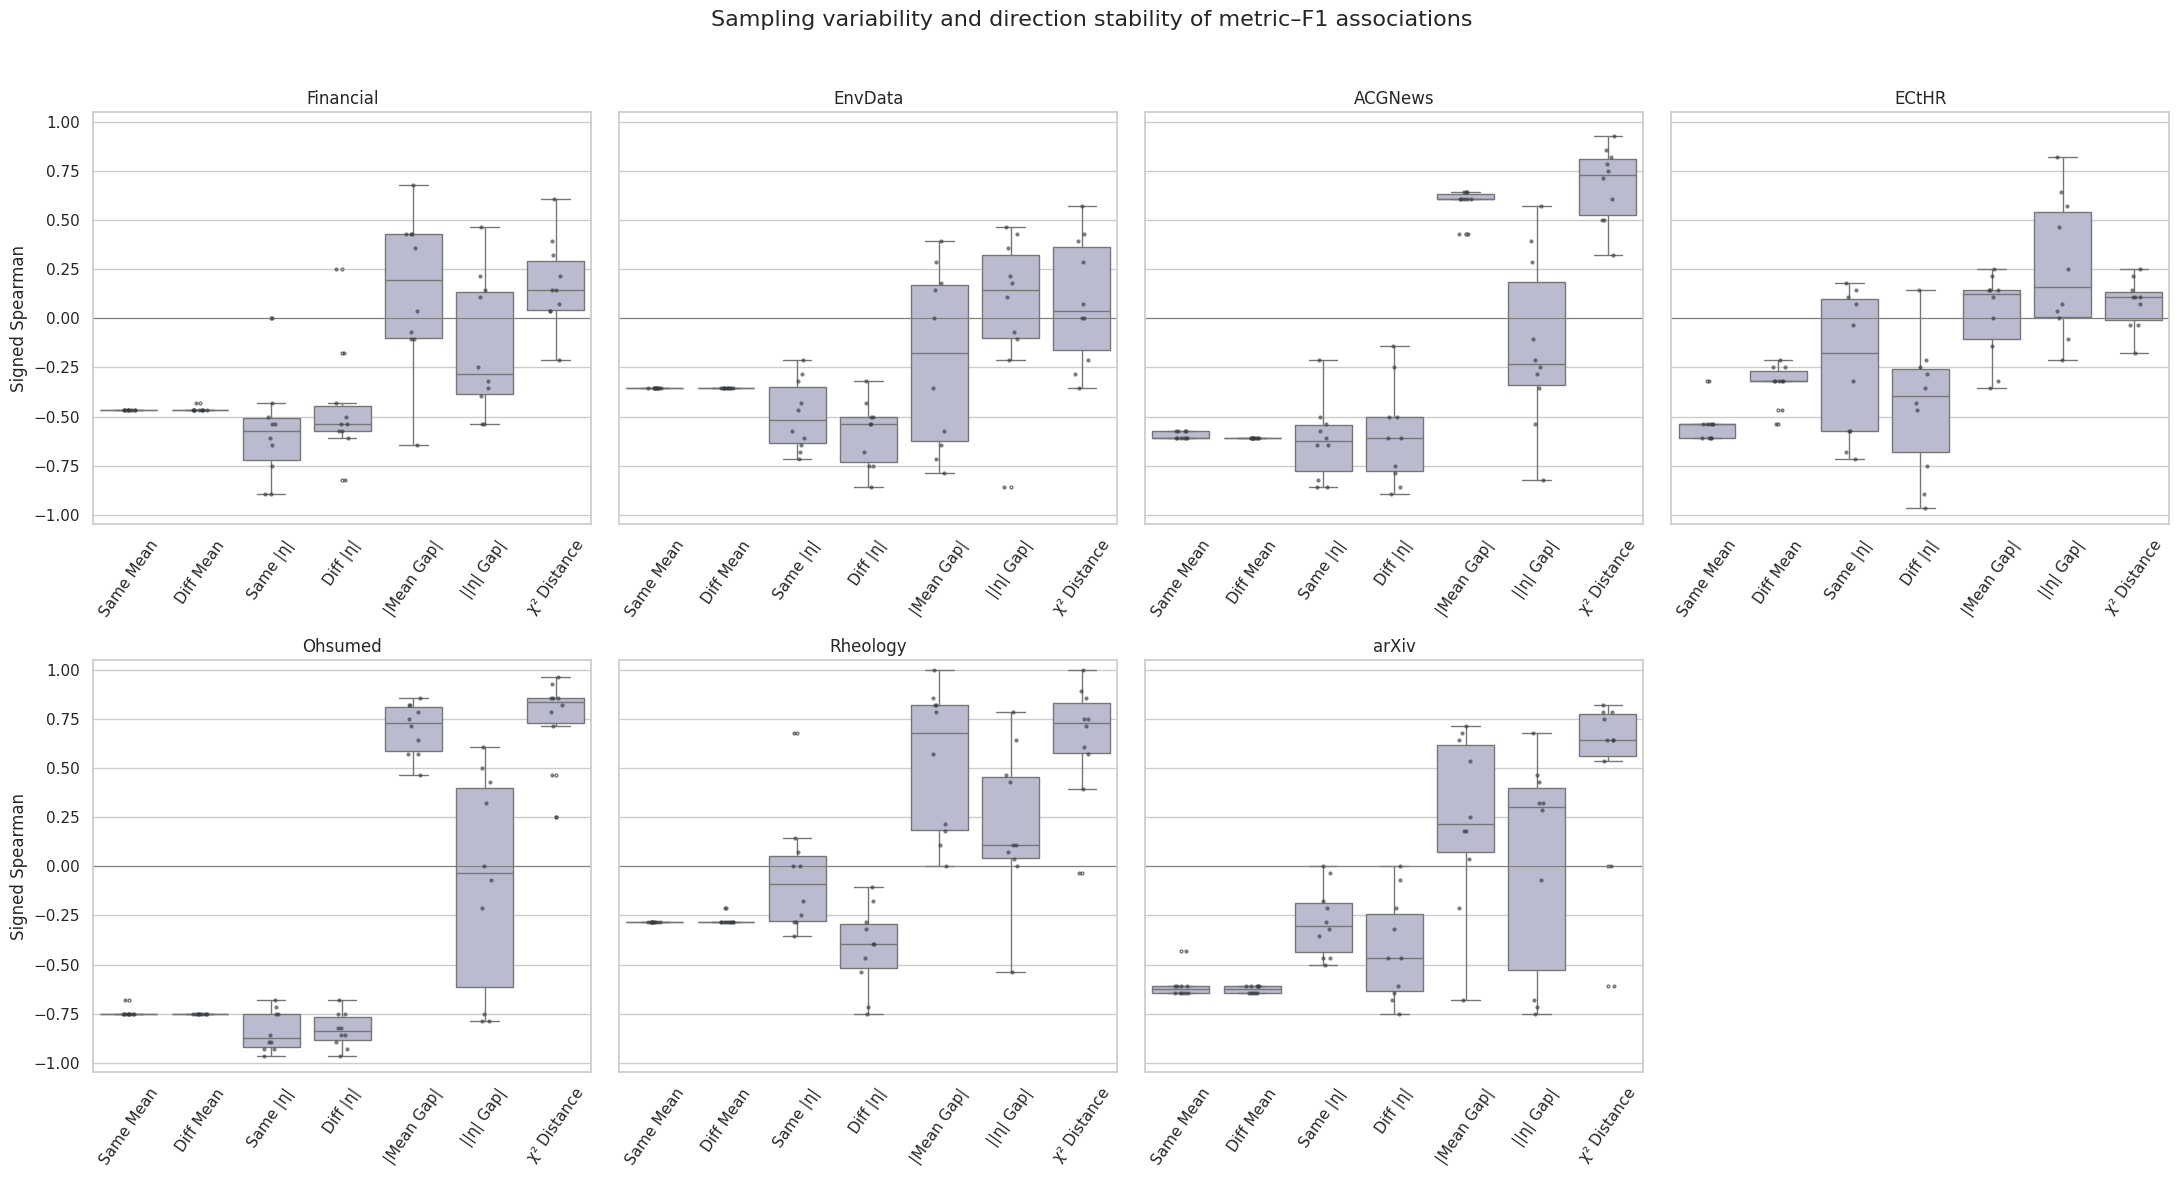

Saved: /home/amyliu/Desktop/GR/Standardizing/results/rank_prediction_uncertainty10_label_first/diagram_results/uncertainty/05_spearman_sampling_distributions.png

Uncertainty diagram output directory:
/home/amyliu/Desktop/GR/Standardizing/results/rank_prediction_uncertainty10_label_first/diagram_results/uncertainty


,figure,meaning
0,01_single_metric_spearman_stability.png,Mean and SD of signed metric–Macro-F1 Spearman across ten samples.
1,02_metric_sampling_deviations.png,Metric sampling deviations relative to between-model separation.
2,03_metric_noise_to_signal.png,Within-model sampling noise divided by between-model signal.
3,04_key_model_pair_stability.png,Rank reversals for actual best-vs-second and best-vs-worst models using Diff |eta|.
4,05_spearman_sampling_distributions.png,Full ten-run distributions and direction changes of signed Spearman.


,dataset,metric,spearman_mean,spearman_sd,spearman_min,spearman_max,positive_rounds,negative_rounds
0,ACGNews,abs_eta_abs_gap,-0.1321,0.4319,-0.8214,0.5714,3,7
1,ACGNews,abs_mean_gap,0.5821,0.0826,0.4286,0.6429,10,0
2,ACGNews,chi2_distance,0.6786,0.1912,0.3214,0.9286,10,0
3,ACGNews,diff_abs_eta,-0.5893,0.2493,-0.8929,-0.1429,0,10
4,ACGNews,diff_mean,-0.6071,0.0000,-0.6071,-0.6071,0,10
5,ACGNews,same_abs_eta,-0.6250,0.1951,-0.8571,-0.2143,0,10
6,ACGNews,same_mean,-0.5929,0.0184,-0.6071,-0.5714,0,10
7,ECtHR,abs_eta_abs_gap,0.2536,0.3517,-0.2143,0.8214,7,2
8,ECtHR,abs_mean_gap,0.0179,0.2184,-0.3571,0.2500,6,3
9,ECtHR,chi2_distance,0.0750,0.1276,-0.1786,0.2500,7,3


In [29]:
# STANDARDIZED_UNCERTAINTY_DIAGRAMS
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr

# This cell only reads completed results. It does not recompute embeddings.
project_root = Path.cwd()
if project_root.name == "Standardizing":
    project_root = project_root.parent

uncertainty_file = (
    project_root
    / "Standardizing/results/rank_prediction_uncertainty10_label_first"
    / "all_datasets_model_metrics_10runs.csv"
)
f1_file = (
    project_root
    / "Standardizing/results/finetuning_8epochs_5fold/model_summary.csv"
)
output_dir = (
    project_root
    / "Standardizing/results/rank_prediction_uncertainty10_label_first"
    / "diagram_results/uncertainty"
)
output_dir.mkdir(parents=True, exist_ok=True)

if not uncertainty_file.exists():
    raise FileNotFoundError(uncertainty_file)
if not f1_file.exists():
    raise FileNotFoundError(f1_file)

uncertainty_df = pd.read_csv(uncertainty_file)
f1_df = pd.read_csv(f1_file)

dataset_order = [
    "Financial", "EnvData", "ACGNews", "ECtHR",
    "Ohsumed", "Rheology", "arXiv",
]
metric_columns = [
    "same_mean", "diff_mean", "same_abs_eta", "diff_abs_eta",
    "abs_mean_gap", "abs_eta_abs_gap", "chi2_distance",
]
core_metrics = [
    "same_mean", "diff_mean", "same_abs_eta",
    "diff_abs_eta", "chi2_distance",
]
metric_labels = {
    "same_mean": "Same Mean",
    "diff_mean": "Diff Mean",
    "same_abs_eta": "Same |η|",
    "diff_abs_eta": "Diff |η|",
    "abs_mean_gap": "|Mean Gap|",
    "abs_eta_abs_gap": "||η| Gap|",
    "chi2_distance": "χ² Distance",
}

required_uncertainty = {
    "dataset", "model", "repetition", *metric_columns,
}
required_f1 = {"dataset", "model", "macro_f1_mean"}
missing_uncertainty = required_uncertainty - set(uncertainty_df.columns)
missing_f1 = required_f1 - set(f1_df.columns)
if missing_uncertainty:
    raise ValueError(f"Missing uncertainty columns: {sorted(missing_uncertainty)}")
if missing_f1:
    raise ValueError(f"Missing F1 columns: {sorted(missing_f1)}")

analysis_df = uncertainty_df.merge(
    f1_df[["dataset", "model", "macro_f1_mean"]],
    on=["dataset", "model"],
    how="left",
    validate="many_to_one",
)
if analysis_df["macro_f1_mean"].isna().any():
    missing = analysis_df.loc[
        analysis_df["macro_f1_mean"].isna(), ["dataset", "model"]
    ].drop_duplicates()
    raise ValueError(f"F1 results were not found for:\n{missing.to_string(index=False)}")

observed_repetitions = analysis_df.groupby("dataset")["repetition"].nunique()
observed_models = analysis_df.groupby("dataset")["model"].nunique()
if not observed_repetitions.eq(10).all():
    raise ValueError(f"Expected 10 repetitions per dataset:\n{observed_repetitions}")
if not observed_models.eq(7).all():
    raise ValueError(f"Expected 7 models per dataset:\n{observed_models}")

sns.set_theme(style="whitegrid", context="notebook")

def save_and_show(fig, filename):
    path = output_dir / filename
    fig.savefig(path, dpi=220, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    print("Saved:", path)


# 1. Repetition-level single-metric Spearman stability
spearman_rows = []
for (dataset, repetition), group in analysis_df.groupby(["dataset", "repetition"]):
    for metric in metric_columns:
        rho = spearmanr(group[metric], group["macro_f1_mean"]).statistic
        spearman_rows.append({
            "dataset": dataset,
            "repetition": int(repetition),
            "metric": metric,
            "spearman": float(rho),
        })

repetition_spearman_df = pd.DataFrame(spearman_rows)
spearman_summary_df = (
    repetition_spearman_df
    .groupby(["dataset", "metric"], as_index=False)
    .agg(
        spearman_mean=("spearman", "mean"),
        spearman_sd=("spearman", "std"),
        spearman_min=("spearman", "min"),
        spearman_max=("spearman", "max"),
        positive_rounds=("spearman", lambda x: int((x > 0).sum())),
        negative_rounds=("spearman", lambda x: int((x < 0).sum())),
    )
)
repetition_spearman_df.to_csv(output_dir / "repetition_spearman.csv", index=False)
spearman_summary_df.to_csv(output_dir / "repetition_spearman_summary.csv", index=False)

mean_matrix = spearman_summary_df.pivot(
    index="dataset", columns="metric", values="spearman_mean"
).reindex(index=dataset_order, columns=metric_columns)
sd_matrix = spearman_summary_df.pivot(
    index="dataset", columns="metric", values="spearman_sd"
).reindex(index=dataset_order, columns=metric_columns)
mean_matrix.columns = [metric_labels[x] for x in mean_matrix.columns]
sd_matrix.columns = [metric_labels[x] for x in sd_matrix.columns]

fig, axes = plt.subplots(1, 2, figsize=(21, 6.5))
sns.heatmap(
    mean_matrix, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
    vmin=-1, vmax=1, linewidths=0.4, ax=axes[0],
)
axes[0].set_title("Mean individual-metric Spearman (signed)")
axes[0].set_xlabel("Metric")
axes[0].set_ylabel("Dataset")
sns.heatmap(
    sd_matrix, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0,
    linewidths=0.4, ax=axes[1],
)
axes[1].set_title("Sampling SD of individual-metric Spearman")
axes[1].set_xlabel("Metric")
axes[1].set_ylabel("Dataset")
for axis in axes:
    axis.tick_params(axis="x", rotation=65)
fig.tight_layout()
save_and_show(fig, "01_single_metric_spearman_stability.png")


# 2. Sampling deviations, scaled by the between-model spread of ten-run means.
# This is the current-data counterpart of the earlier contribution boxplots.
deviation_rows = []
for dataset, dataset_group in analysis_df.groupby("dataset"):
    for metric in core_metrics:
        model_means = dataset_group.groupby("model")[metric].mean()
        between_model_sd = model_means.std(ddof=1)
        scale = between_model_sd if np.isfinite(between_model_sd) and between_model_sd > 0 else 1.0
        centers = dataset_group.groupby("model")[metric].transform("mean")
        values = (dataset_group[metric] - centers) / scale
        for value in values:
            deviation_rows.append({
                "dataset": dataset,
                "metric": metric,
                "standardized_sampling_deviation": float(value),
            })

metric_deviation_df = pd.DataFrame(deviation_rows)
metric_deviation_df.to_csv(output_dir / "metric_sampling_deviations.csv", index=False)

fig, axes = plt.subplots(2, 4, figsize=(22, 12), sharey=True)
for axis, dataset in zip(axes.flat, dataset_order):
    subset = metric_deviation_df[metric_deviation_df["dataset"] == dataset].copy()
    subset["metric_label"] = subset["metric"].map(metric_labels)
    sns.boxplot(
        data=subset, x="metric_label", y="standardized_sampling_deviation",
        order=[metric_labels[x] for x in core_metrics],
        color="#9acb95", fliersize=2, ax=axis,
    )
    axis.axhline(0, color="gray", linewidth=0.8)
    axis.set_title(dataset)
    axis.set_xlabel("")
    axis.set_ylabel("Sampling deviation / between-model SD")
    axis.tick_params(axis="x", rotation=45)
axes.flat[-1].axis("off")
fig.suptitle(
    "Metric sampling uncertainty across models and ten repetitions",
    fontsize=16,
)
fig.tight_layout(rect=[0, 0, 1, 0.96])
save_and_show(fig, "02_metric_sampling_deviations.png")


# 3. Noise-to-signal ratio: within-model sampling SD / between-model SD.
noise_rows = []
for (dataset, metric), group in (
    analysis_df.melt(
        id_vars=["dataset", "model", "repetition"],
        value_vars=core_metrics,
        var_name="metric",
        value_name="value",
    ).groupby(["dataset", "metric"])
):
    within_sd = group.groupby("model")["value"].std(ddof=1).mean()
    between_sd = group.groupby("model")["value"].mean().std(ddof=1)
    ratio = within_sd / between_sd if between_sd > 0 else np.nan
    noise_rows.append({
        "dataset": dataset,
        "metric": metric,
        "mean_within_model_sd": within_sd,
        "between_model_sd": between_sd,
        "noise_to_signal_ratio": ratio,
    })

noise_ratio_df = pd.DataFrame(noise_rows)
noise_ratio_df.to_csv(output_dir / "metric_noise_to_signal.csv", index=False)
ratio_matrix = noise_ratio_df.pivot(
    index="dataset", columns="metric", values="noise_to_signal_ratio"
).reindex(index=dataset_order, columns=core_metrics)
ratio_matrix.columns = [metric_labels[x] for x in ratio_matrix.columns]

fig, axis = plt.subplots(figsize=(10.5, 6.5))
sns.heatmap(
    ratio_matrix, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0,
    linewidths=0.5, ax=axis,
)
axis.set_title("Sampling noise / between-model signal (lower is more stable)")
axis.set_xlabel("Metric")
axis.set_ylabel("Dataset")
axis.tick_params(axis="x", rotation=45)
fig.tight_layout()
save_and_show(fig, "03_metric_noise_to_signal.png")


# 4. Key model-pair stability using Diff |eta| (lower is better).
# Positive differences mean the better Macro-F1 model is correctly ranked ahead.
def short_model_name(model_name):
    tail = str(model_name).split("/")[-1].lower()
    aliases = {
        "bert-base-uncased": "BERT",
        "scibert_scivocab_uncased": "SciBERT",
        "legal-bert-base-uncased": "LegalBERT",
        "finbert-tone": "FinancialBERT",
        "pharmbert-uncased": "PharmBERT",
        "agriculture-bert-uncased": "AgricultureBERT",
        "chemical-bert-uncased": "ChemicalBERT",
    }
    return aliases.get(tail, str(model_name).split("/")[-1])

pair_rows = []
for dataset in dataset_order:
    f1_ranking = (
        f1_df[f1_df["dataset"] == dataset]
        .sort_values("macro_f1_mean", ascending=False)
    )
    best_model = f1_ranking.iloc[0]["model"]
    second_model = f1_ranking.iloc[1]["model"]
    worst_model = f1_ranking.iloc[-1]["model"]
    dataset_metrics = analysis_df[analysis_df["dataset"] == dataset]
    pivot = dataset_metrics.pivot(index="repetition", columns="model", values="diff_abs_eta")
    for comparison, other_model in [("Best vs second", second_model), ("Best vs worst", worst_model)]:
        # Lower Diff |eta| is treated as the better metric score.
        delta = (-pivot[best_model]) - (-pivot[other_model])
        for repetition, value in delta.items():
            pair_rows.append({
                "dataset": dataset,
                "repetition": int(repetition),
                "comparison": comparison,
                "model_pair": f"{short_model_name(best_model)} - {short_model_name(other_model)}",
                "oriented_score_difference": float(value),
                "correct_order": bool(value > 0),
            })

key_pair_df = pd.DataFrame(pair_rows)
key_pair_df.to_csv(output_dir / "key_model_pair_stability.csv", index=False)

fig, axes = plt.subplots(2, 4, figsize=(22, 11))
for axis, dataset in zip(axes.flat, dataset_order):
    subset = key_pair_df[key_pair_df["dataset"] == dataset]
    for (comparison, pair_name), line in subset.groupby(["comparison", "model_pair"]):
        axis.plot(
            line["repetition"], line["oriented_score_difference"],
            marker="o", linewidth=1.8, markersize=4,
            label=f"{comparison}: {pair_name}",
        )
    axis.axhline(0, color="gray", linestyle="--", linewidth=1.2)
    axis.set_title(dataset)
    axis.set_xlabel("Repetition")
    axis.set_ylabel("Oriented Diff |η| difference")
    axis.set_xticks(range(1, 11))
    axis.legend(fontsize=7)
axes.flat[-1].axis("off")
fig.suptitle(
    "Key model-pair stability (positive = better F1 model ranked ahead)",
    fontsize=16,
)
fig.tight_layout(rect=[0, 0, 1, 0.96])
save_and_show(fig, "04_key_model_pair_stability.png")


# 5. Full distributions of repetition-level signed Spearman coefficients.
plot_spearman = repetition_spearman_df.copy()
plot_spearman["metric_label"] = plot_spearman["metric"].map(metric_labels)
fig, axes = plt.subplots(2, 4, figsize=(22, 12), sharey=True)
for axis, dataset in zip(axes.flat, dataset_order):
    subset = plot_spearman[plot_spearman["dataset"] == dataset]
    sns.boxplot(
        data=subset, x="metric_label", y="spearman",
        order=[metric_labels[x] for x in metric_columns],
        color="#b7b8d2", fliersize=2, ax=axis,
    )
    sns.stripplot(
        data=subset, x="metric_label", y="spearman",
        order=[metric_labels[x] for x in metric_columns],
        color="#343a40", size=3, alpha=0.65, ax=axis,
    )
    axis.axhline(0, color="gray", linewidth=0.8)
    axis.set_ylim(-1.05, 1.05)
    axis.set_title(dataset)
    axis.set_xlabel("")
    axis.set_ylabel("Signed Spearman")
    axis.tick_params(axis="x", rotation=55)
axes.flat[-1].axis("off")
fig.suptitle("Sampling variability and direction stability of metric–F1 associations", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
save_and_show(fig, "05_spearman_sampling_distributions.png")


figure_manifest = pd.DataFrame([
    {"figure": "01_single_metric_spearman_stability.png", "meaning": "Mean and SD of signed metric–Macro-F1 Spearman across ten samples."},
    {"figure": "02_metric_sampling_deviations.png", "meaning": "Metric sampling deviations relative to between-model separation."},
    {"figure": "03_metric_noise_to_signal.png", "meaning": "Within-model sampling noise divided by between-model signal."},
    {"figure": "04_key_model_pair_stability.png", "meaning": "Rank reversals for actual best-vs-second and best-vs-worst models using Diff |eta|."},
    {"figure": "05_spearman_sampling_distributions.png", "meaning": "Full ten-run distributions and direction changes of signed Spearman."},
])
figure_manifest.to_csv(output_dir / "figure_manifest.csv", index=False)

print("\nUncertainty diagram output directory:")
print(output_dir)
display(figure_manifest)
display(spearman_summary_df.round(4))
